# Modül 1a — OpenCV Core, problem sırasıyla

**Durum (2026-11-04):** 25/25 egzersizin kodu yazılmış. Bu sürümde hiçbir kod hücresi ve çıktı silinmedi; egzersizler 8 problemin altına toplandı. Açık işler: 13 gözlem cümlesi, inceleme notları (Ex 1 ve Ex 9 için iki yeni not eklendi) ve her problemin sonundaki araç fonksiyonu.

**Yapı:** Her problem bir soruyla başlıyor; egzersizler o sorunun adımları. Her problemin sonunda tek bir somut çıktı var: `cvtools.py` içine yazdığın bir araç ve onu sınayan bir test hücresi. **Test hücresi hatasız çalışıp `✓` yazınca o problem bitti.**

**Oturum kuralı:** 1 oturum = 1 problem.
1. O problemdeki eksik gözlemleri ve inceleme notlarını kapat.
2. Aracı `cvtools.py`'ye yaz (dosya bu notebook'la aynı klasörde).
3. Test hücresini çalıştır.
4. `PROGRESS.md`'ye tek satır: hangi problem, test geçti mi, nerede takıldım.

**AI kuralı (değişmedi):** Önce kendin dene; AI sadece ipucu ve inceleme için.

Kaynak: Week 2 OpenCV + Kaggle workbook, [OpenCV Tutorial: From Basic to Advanced](https://www.kaggle.com/code/talhabu/opencv-tutorial-from-basic-to-advanced).

**Görseller:** `images/test.jpg`, `images/star.png`, `images/overexposure.png`, `images/underexposure.png`. Final problem için ayrıca `images/facade.jpg`: kendi seçtiğin bir cephe fotoğrafı.

## Problem zinciri

```text
P1  Bilgisayar bu fotoğrafı nasıl görüyor?        → load_bgr, show
P2  Sadece bir bölgeyle nasıl çalışırım?          → color_mask, apply_mask
P3  Hangi renk kanalı bilgi taşıyor?              → excess_green
P4  Bu fotoğrafın ışığı neden kötü?               → diagnose_exposure
P5  Gürültüyü atıp kenarı nasıl korurum?          → smooth
P6  Bir şeyi arka plandan nasıl ayırırım?         → binarize
P7  Sınır nerede?                                 → edge_map
P8  Bu sınırlar kaç nesne, nerede?                → find_boxes, draw_boxes
         │
         ▼
FINAL  Bir cephe fotoğrafında pencere adaylarını bul ve say  (bütün araçlar)
         │
         ▼
Sonra: Modül 1b (morfoloji, Ex 31–32) → final v2 → arzu yolları projesi
```

## Her araç ileride nerede kullanılacak

| Araç | Final (cephe) | Arzu yolları | Render pipeline'ların |
|---|---|---|---|
| `load_bgr`, `show` | her adım | her adım | her adım |
| `color_mask` | gökyüzünü cepheden ayırmak | çimen ↔ toprak (HSV yeşil aralığı) | ImageToRender: eleman bölgesini ayırmak |
| `excess_green` | cepheyi kapatan ağaçları maskelemek | bitki örtüsü haritası; patika = yeşilin kesildiği yer | — |
| `diagnose_exposure` | gölgede/güneşte çekilmiş cepheler | farklı saatte çekilmiş hava fotoğrafları | telefonla çekilmiş eskiz kağıtları |
| `smooth` | sıva dokusunu bastırmak | çim dokusunu bastırmak | Canny öncesi temizlik |
| `binarize` | koyu cam ↔ açık duvar | açık toprak ↔ koyu çimen | SketchToRender: eşit ışıklanmamış kağıdı temiz çizgiye çevirmek |
| `edge_map` | pencere kasası, lento, döşeme çizgisi | patika kenarları | ControlNet Canny koşul görüntüsü |
| `find_boxes` | pencere sayımı ve konumu | patika parçalarını ölçmek | ImageToRender: eleman adayları |

In [1]:
%matplotlib inline
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path


IMAGE_PATH = Path("images/test.jpg")
OUTPUT_DIR = Path("cv_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

print("OpenCV:", cv2.__version__)


OpenCV: 5.0.0


# Problem 1 — Bilgisayar bu fotoğrafı nasıl görüyor?

**Soru:** Ekranda bir ördek görüyorum. Python'un elinde ne var: hangi sayılar, hangi sırayla, hangi tipte?

**Çıktı (araç):** `load_bgr(path)`, `show(*images, titles=None)`

**Neden lazım:** Bundan sonraki her problem bir görüntü okuyup göstermekle başlıyor. Ex 2–3'teki BGR/RGB karışıklığı ve her hücrede tekrar eden `subplots` kodu bu iki araçla bir kez çözülüyor.

### 1.1 (Ex 1) — Oku ve incele
`cv2.imread()` ile oku. Bak: `type`, `shape`, `dtype`, `min`, `max`, `mean`. Okuma başarısız olursa ne döndüğünü kontrol et (ipucu: hata vermiyor).

In [2]:
# TODO
# read the image using OpenCV
img=cv2.imread("images/test.jpg")


> **İnceleme (2026-11-04):** Hücre görüntüyü okuyor ama istenen altı değer yazdırılmamış. `load_bgr` aracının neden `None` kontrolü yapması gerektiği de bu adımdan çıkıyor: yanlış bir yol `imread`'de sessizce `None` döndürüyor, hata ancak birkaç hücre sonra anlaşılmaz bir yerde patlıyor.

### 1.2 (Ex 2) — BGR ve RGB
1. Bir pikseli yazdır. 2. `cv2.cvtColor` ile BGR → RGB çevir. 3. Matplotlib'de doğru göster. 4. BGR görüntüyü doğrudan Matplotlib'e verince ne olduğunu da göster.

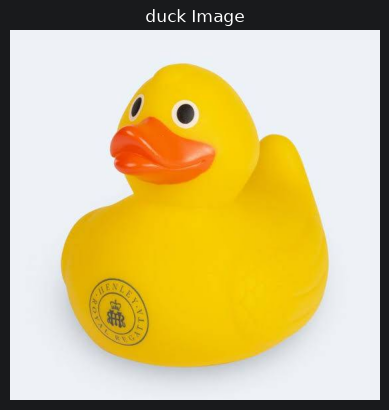

In [3]:
# TODO
# convert the color from BGR to RGB for displaying using matplotlib
img_rgb=cv2.cvtColor(img, cv2.COLOR_BGR2RGB)


# display the image using matplotlib
plt.imshow(img_rgb)
plt.title("duck Image")
plt.axis('off')
plt.show()

**Gözlem 1.2 (Ex 2)** — BGR görüntüyü doğrudan Matplotlib'e verince renkler neden değişiyor? (Yanlış hali de yan yana göster.) _(eksik)_

> ...

### 1.3 (Ex 3) — Gri tonlama
Orijinal ve gri görüntünün `shape` ve `dtype` değerlerini karşılaştır.

(np.float64(-0.5), np.float64(553.5), np.float64(553.5), np.float64(-0.5))

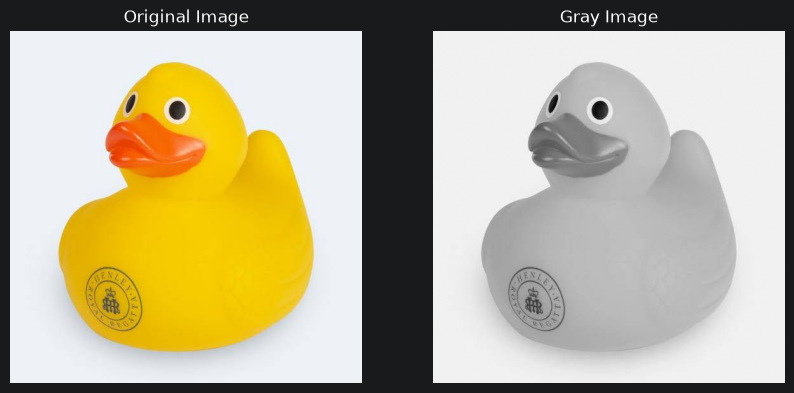

In [4]:
# TODO
img=img_rgb

# Converting the image to grayscale
img_gray=cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)

fig, axs = plt.subplots(1,2,figsize=(10,10))
axs[0].imshow(img)
axs[0].set_title("Original Image")
axs[1].imshow(img_gray,cmap="gray")
axs[1].set_title("Gray Image")
axs[0].axis('off')
axs[1].axis('off')


> **İnceleme (2026-11-02):** `img = img_rgb` satırından sonra `img` artık RGB; sonraki hücreler `img`'yi BGR sanarsa renkler karışır. Global bir değişkeni tip değiştirerek yeniden kullanma; `img_bgr` / `img_rgb` diye ayrı isimler kullan.

**Gözlem 1.3 (Ex 3)** — `(H, W, 3)` neden `(H, W)` oluyor? _(eksik)_

> ...

### 1.4 (Ex 4) — NumPy ortalaması ile OpenCV grisi
`image.mean(axis=2)` ile `cv2.cvtColor(..., COLOR_BGR2GRAY)` sonucunu karşılaştır. Değerlerin aynı çıkmasını bekleme.

(np.float64(-0.5), np.float64(553.5), np.float64(553.5), np.float64(-0.5))

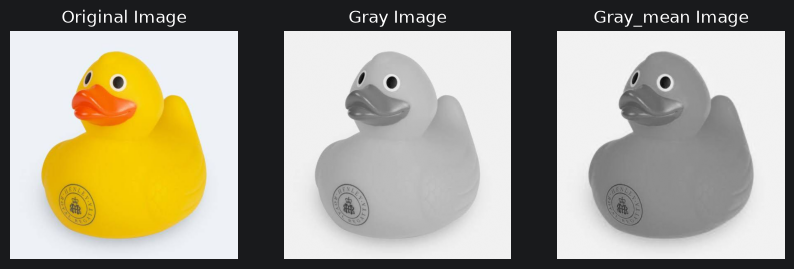

In [5]:
# TODO
gray_mean = img.mean(axis=2)# additional grayscale method
# Converting the image to grayscale
img_gray=cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)

fig, axs = plt.subplots(1,3,figsize=(10,10))
axs[0].imshow(img)
axs[0].set_title("Original Image")
axs[1].imshow(img_gray,cmap="gray")
axs[1].set_title("Gray Image")
axs[2].imshow(gray_mean,cmap="gray")
axs[2].set_title("Gray_mean Image")
axs[0].axis('off')
axs[1].axis('off')
axs[2].axis('off')

**Gözlem 1.4 (Ex 4)** — İki gri tonlama neden aynı değil? _(eksik)_

> ...

### Araç 1 — `load_bgr`, `show`
`cvtools.py`'de iki fonksiyonu yaz:
- `load_bgr(path)`: BGR görüntü döndürür. Dosya okunamazsa `None` döndürmek yerine `FileNotFoundError` fırlatır.
- `show(*images, titles=None)`: görüntüleri yan yana gösterir. 2 boyutlu görüntüyü gri renk haritasıyla, 3 boyutluyu BGR → RGB çevirerek gösterir; eksenleri kapatır.

Alttaki hücre hatasız çalışıp ördek doğru renklerde görünüyorsa Problem 1 bitti.

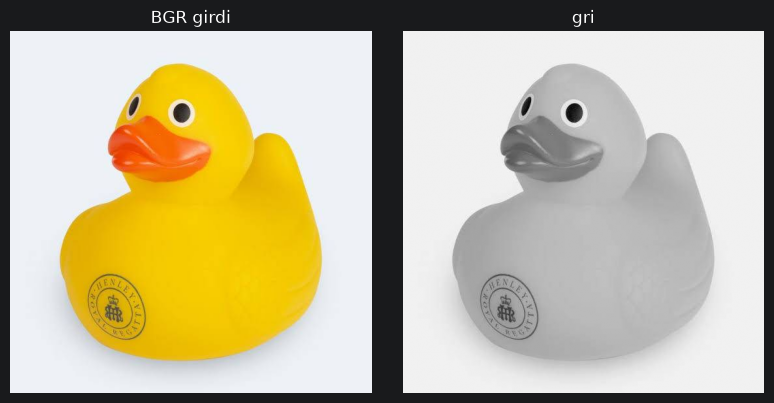

Problem 1 ✓


In [6]:
import importlib, cvtools; importlib.reload(cvtools)
from cvtools import load_bgr, show

img = load_bgr("images/test.jpg")
assert img.ndim == 3 and img.shape[2] == 3, "renkli görüntü (H, W, 3) bekleniyor"
assert img.dtype == np.uint8

try:
    load_bgr("images/olmayan_dosya.jpg")
    raise AssertionError("olmayan dosyada FileNotFoundError bekleniyordu")
except FileNotFoundError:
    pass

show(img, cv2.cvtColor(img, cv2.COLOR_BGR2GRAY), titles=["BGR girdi", "gri"])
print("Problem 1 ✓")

# Problem 2 — Fotoğrafın sadece bir bölgesiyle nasıl çalışırım?

**Soru:** Görüntünün tamamı değil bir parçası önemliyse (bir cephe, bir pencere, sarı bir ördek), geri kalanını nasıl dışarıda bırakırım?

**Çıktı (araç):** `color_mask(bgr, lower_hsv, upper_hsv)`, `apply_mask(bgr, mask)`

**Neden lazım:** Maske, "nereye bakacağım" sorusunun cevabı. Finalde gökyüzünü cepheden, arzu yollarında çimeni topraktan bu araçla ayıracaksın.

Maske değerleri: `0` dışarıda, `255` seçili.

### 2.1 (Ex 5) — Dikdörtgen maske
Görüntüyle aynı boyutta siyah bir maske oluştur, bir dikdörtgeni beyaz yap, bitwise işlemle uygula. Orijinal, maske ve sonucu göster.

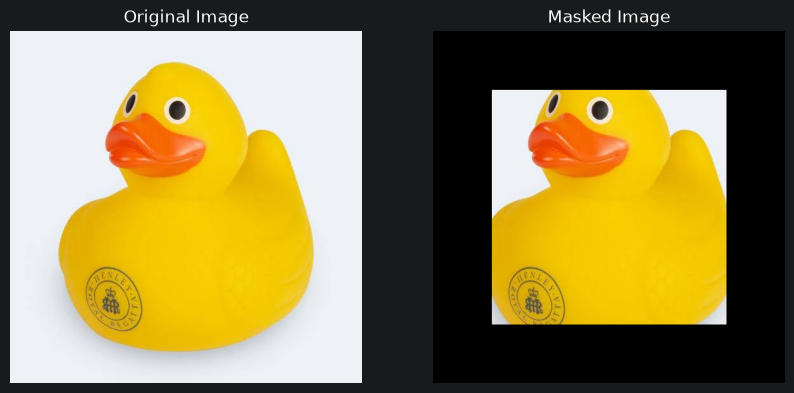

In [7]:
# TODO
# Create a black mask with the same size as the image
mask=np.zeros_like(img)

# Define the measurements of rectangle
height, width = img.shape[:2] #[h,w,c] --> (h,w)
x1=width//2 -width//3
x2=width//2 +width//3
y1=height//2 -height//3
y2=height//2 +height//3


# Draw a white circle in the mask
cv2.rectangle(mask, (x1,y1), (x2,y2), (255, 255, 255), -1)

# Apply the mask to the image
masked_image = cv2.bitwise_and(cv2.cvtColor(img, cv2.COLOR_BGR2RGB), mask)

# Display the original image with the circular mask
fig,axs= plt.subplots(1,2,figsize=(10, 5))
axs[0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
axs[0].set_title("Original Image")
axs[1].imshow(masked_image)
axs[1].set_title("Masked Image")
axs[0].axis('off')
axs[1].axis('off')
plt.show()


> **İnceleme (2026-11-02):** Bu hücrenin başındaki ML taksonomisi notu yukarıya ayrı bir markdown hücresine taşındı. Yorumlarda "circle" yazıyor ama çizilen bir dikdörtgen; yorumu düzelt.

**Ek deneme — yıldız maskesi:** Başka bir görüntüden çıkarılan şekli maske olarak kullanmak. Bu hücre Problem 8'deki kontür araçlarını şimdiden kullanıyor.

Number of contours: 1


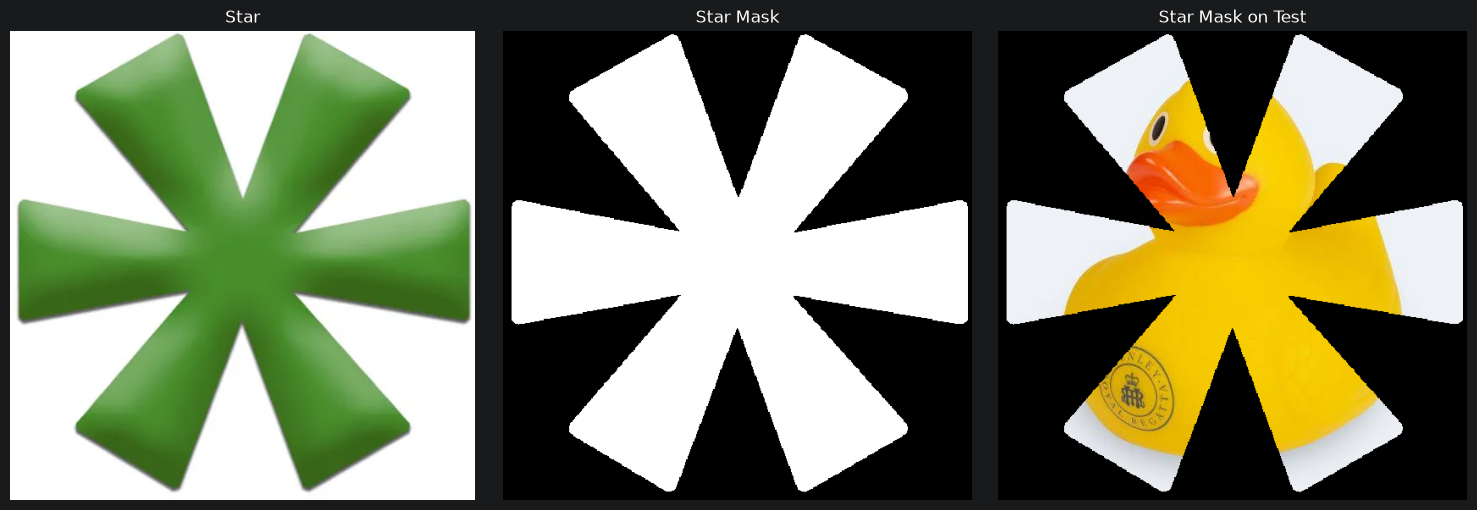

In [8]:
# --------------------------------------------------
# 1. Read images
# --------------------------------------------------

star = cv2.imread("images/star.png")
test = cv2.imread("images/test.jpg")

# --------------------------------------------------
# 2. STAR IMAGE -> binary
# --------------------------------------------------

star_gray = cv2.cvtColor(star, cv2.COLOR_BGR2GRAY)

_, star_binary = cv2.threshold(
    star_gray,
    200, # threshold value determines wheter the pixel is 0 or 255
    255, # max value
    cv2.THRESH_BINARY_INV
)

# --------------------------------------------------
# 3. Find star contour
# --------------------------------------------------

contours, hierarchy = cv2.findContours(
    star_binary,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

print("Number of contours:", len(contours))

# Largest contour
star_contour = max(contours, key=cv2.contourArea)

# --------------------------------------------------
# 4. Create STAR mask
# --------------------------------------------------

star_mask = np.zeros_like(star_gray)

cv2.drawContours(
    star_mask,
    [star_contour],
    -1,
    255,
    -1
)

# --------------------------------------------------
# 5. Resize STAR mask to TEST image size
# --------------------------------------------------

test_h, test_w = test.shape[:2]

mask = cv2.resize(
    star_mask,
    (test_w, test_h),
    interpolation=cv2.INTER_NEAREST
)

# --------------------------------------------------
# 6. Apply STAR mask to TEST image
# --------------------------------------------------

masked_test = cv2.bitwise_and(
    test,
    test,
    mask=mask
)

# --------------------------------------------------
# 7. Display
# --------------------------------------------------

fig, axs = plt.subplots(1, 3, figsize=(15, 5))

axs[0].imshow(
    cv2.cvtColor(star, cv2.COLOR_BGR2RGB)
)
axs[0].set_title("Star")

axs[1].imshow(
    mask,
    cmap="gray"
)
axs[1].set_title("Star Mask")

axs[2].imshow(
    cv2.cvtColor(masked_test, cv2.COLOR_BGR2RGB)
)
axs[2].set_title("Star Mask on Test")

for ax in axs:
    ax.axis("off")

plt.tight_layout()
plt.show()

### 2.2 (Ex 6) — Anlamlı bir bölgeyi maskele
Görüntüde anlamlı bir şey seç (cephe, pencere, yol, araç, tabela ya da burada sarı ördek), maskesini oluştur ve sonucu kaydet.

In [9]:
# TODO
duck_img = cv2.imread("images/test.jpg")

duck_hsv = cv2.cvtColor(duck_img, cv2.COLOR_BGR2HSV)

samples = []


def mause_callback(event, x, y, flags, param):
    if event == cv2.EVENT_LBUTTONDOWN:
        H, S, V = duck_hsv[y, x]
        samples.append((x, y, H, S, V))

        print(
            f"Clicked: (x={x}, y={y}) | "
            f"HSV=({H}, {S}, {V})"
        )


cv2.namedWindow("Image")
cv2.setMouseCallback("Image", mause_callback)
while True:
    # Her frame'de orijinal görüntüden yeniden başla
    display = duck_img.copy()
    # Daha önce tıklanan noktaları ve bilgilerini göster
    for i, (x, y, H, S, V) in enumerate(samples, start=1):
        cv2.circle(display, (x, y), 3, (255, 255, 255), -1)

        cv2.putText(
            display,
            f"#{i} ({x},{y}) HSV:{H},{S},{V}",
            (x + 5, y - 5),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.45,
            (255, 255, 255),
            1
        )
    cv2.imshow("Image", display)

    key = cv2.waitKey(20) & 0xFF

    # ESC
    if key == 27:
        break

    # X ile kapatıldı mı?
    if cv2.getWindowProperty("Image", cv2.WND_PROP_VISIBLE) < 1:
        break

cv2.destroyAllWindows()




Clicked: (x=345, y=310) | HSV=(25, 253, 245)


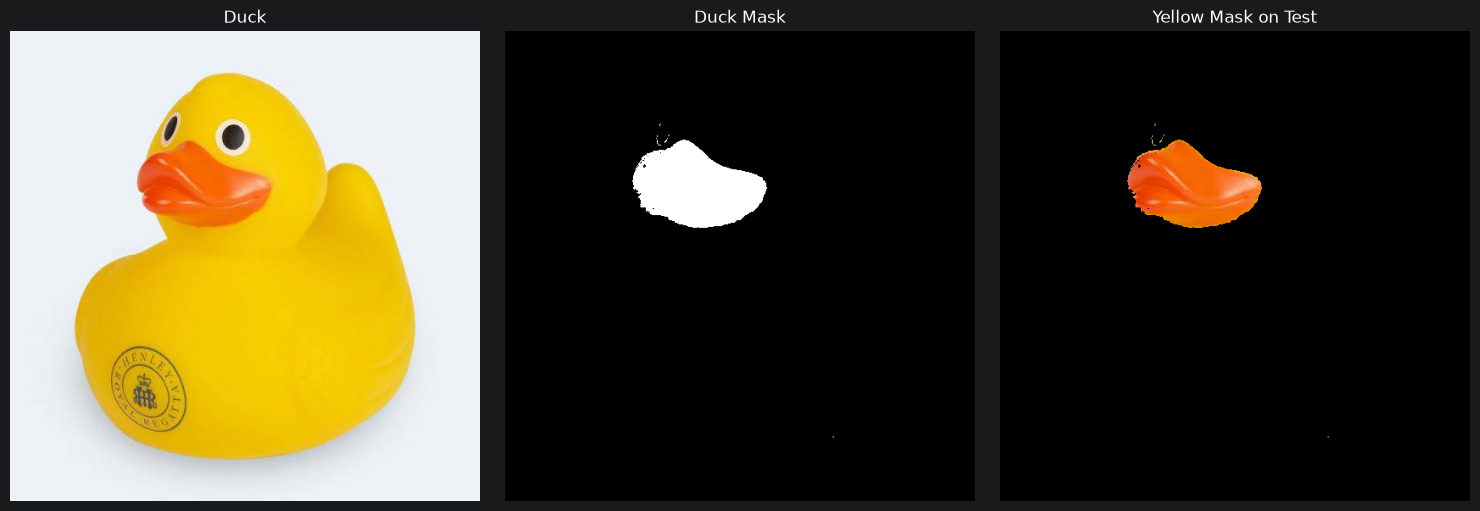

True

In [10]:
def create_mask(hsv,lower,upper):
    mask_cv2 = cv2.inRange(hsv, lower, upper)
    return mask_cv2

#lower_yellow =np.array([22,170,200])
#upper_yellow =np.array([27,255,255])

lower_yellow =np.array([6,100,200])
upper_yellow =np.array([18,255,255])

duck_yellow_binary = create_mask(
    duck_hsv,
    lower_yellow,
    upper_yellow
)


ducky_h, ducky_w = duck_img.shape[:2]

ducky_mask = cv2.resize(
    duck_yellow_binary,
    (ducky_w, ducky_h),
    interpolation=cv2.INTER_NEAREST
)

masked_duck_yellow = cv2.bitwise_and(
    duck_img,
    duck_img,
    mask=ducky_mask
)


fig, axs = plt.subplots(1, 3, figsize=(15, 5))

axs[0].imshow(
    cv2.cvtColor(duck_img, cv2.COLOR_BGR2RGB)
)
axs[0].set_title("Duck")

axs[1].imshow(
    duck_yellow_binary,
    cmap="gray"
)
axs[1].set_title("Duck Mask")

axs[2].imshow(
    cv2.cvtColor(masked_duck_yellow, cv2.COLOR_BGR2RGB)
)
axs[2].set_title("Yellow Mask on Test")

for ax in axs:
    ax.axis("off")

plt.tight_layout()
plt.show()

import os
os.makedirs("outputs", exist_ok=True)
cv2.imwrite("outputs/duck_yellow_mask.png", duck_yellow_binary)


> **İnceleme (2026-11-02):** Tıkladığın piksel `HSV=(25, 252, 244)` ama kullandığın aralık `H 6–18`; yorumdaki `H 22–27` ise tıklamayla uyumlu. Hangi bölgeyi hedeflediğini ve aralığı neden seçtiğini bir cümleyle yaz, tıklama örneklerini de buraya not et. Mouse callback sadece yerel Jupyter'de pencere açar; değerler not edilmezse deney tekrarlanamaz.

**Gözlem 2.2 (Ex 6)** — ROI maskesi bir CV pipeline'ında neden işe yarar? _(eksik)_

> ...

### Araç 2 — `color_mask`, `apply_mask`
- `color_mask(bgr, lower_hsv, upper_hsv)`: BGR alır, kendi içinde HSV'ye çevirir, `cv2.inRange` uygular. `(H, W)` boyutunda, sadece 0 ve 255 içeren `uint8` maske döndürür.
- `apply_mask(bgr, mask)`: maskenin 0 olduğu pikselleri siyah yapar, geri kalanı aynen bırakır.

Alttaki hücrede gerçek görüntü için kullanılan aralığı, Ex 6 inceleme notundaki kararına göre güncelle.

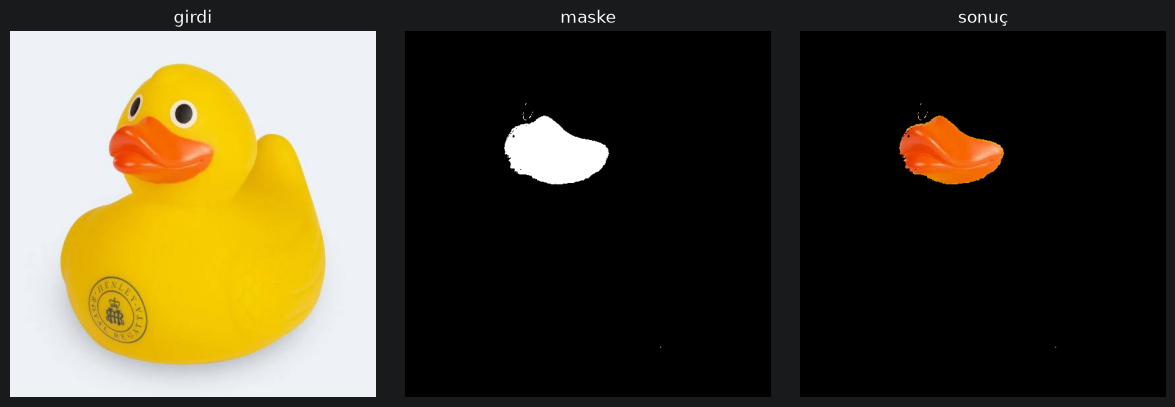

Problem 2 ✓


In [11]:
import importlib, cvtools; importlib.reload(cvtools)
from cvtools import color_mask, apply_mask, load_bgr, show

# Sentetik test: sol yarı sarı, sağ yarı mavi (BGR)
t = np.zeros((10, 20, 3), np.uint8)
t[:, :10] = (0, 255, 255)
t[:, 10:] = (255, 0, 0)
m = color_mask(t, (20, 100, 100), (40, 255, 255))
assert m.shape == (10, 20) and m.dtype == np.uint8, "maske (H, W) ve uint8 olmalı"
assert set(np.unique(m)) <= {0, 255}, "maske sadece 0 ve 255 içermeli"
assert m[:, :10].all() and not m[:, 10:].any(), "sarı seçilmeli, mavi seçilmemeli"
out = apply_mask(t, m)
assert (out[:, 10:] == 0).all() and (out[:, :10] == t[:, :10]).all()

# Gerçek görüntü
duck = load_bgr("images/test.jpg")
duck_m = color_mask(duck, (6, 100, 200), (18, 255, 255))   # aralığını Ex 6 kararına göre güncelle
show(duck, duck_m, apply_mask(duck, duck_m), titles=["girdi", "maske", "sonuç"])
print("Problem 2 ✓")

# Problem 3 — Hangi renk kanalı bilgi taşıyor?

**Soru:** Renkli bir görüntü, üst üste binmiş üç gri görüntü. Aradığım şey (bitki, gökyüzü, sarı ördek) bu kanallardan hangisinde ya da hangi birleşiminde en net görünüyor?

**Çıktı (araç):** `excess_green(bgr)`: bitki örtüsünü öne çıkaran kanal birleşimi.

**Neden lazım:** Arzu yolları projesinin ilk aracı bu. Hava fotoğrafında patika, yeşilin kesildiği yer; `2G − R − B` (Excess Green indeksi) yeşili tek bir gri görüntüde topluyor. Finalde cepheyi kapatan ağaçları maskelemek için de kullanılabilir.

### 3.1 (Ex 7) — Kanalları ayır
`cv2.split()` ile üç kanalı ayrı ayrı göster, yoğunluklarını gözle karşılaştır.

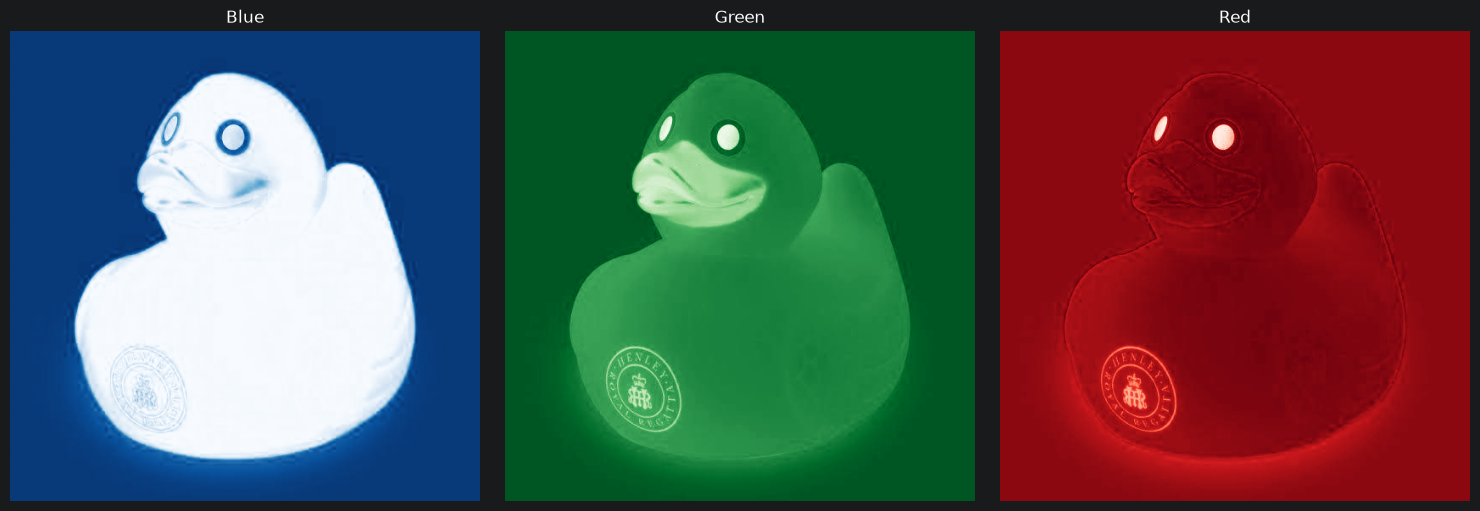

In [12]:
# TODO
duck_img = cv2.imread("images/test.jpg")
B,G,R=cv2.split(duck_img)

fig, axs = plt.subplots(1, 3, figsize=(15, 5))

axs[0].imshow(B, cmap="Blues")
axs[0].set_title("Blue")

axs[1].imshow(G, cmap="Greens")
axs[1].set_title("Green")

axs[2].imshow(R, cmap="Reds")
axs[2].set_title("Red")

for ax in axs:
    ax.axis("off")

plt.tight_layout()
plt.show()

### 3.2 (Ex 8) — Kanallara NumPy ile eriş
`image[:, :, 0]`, `[:, :, 1]`, `[:, :, 2]`. OpenCV'de sıra **BGR**: indeks 0 mavi.

In [13]:
# TODO
duck_img[:,:,0]
duck_img[:,:,1]
duck_img[:,:,2]

duck_img.shape

duck_img[250,300,2]
duck_img[250,300]

array([  1, 200, 246], dtype=uint8)

### 3.3 (Ex 9) — Kanalları değiştirip birleştir
Bir kanalı bastır, artır ya da iki kanalı yer değiştir; `cv2.merge()` ile birleştir. Görsel etkiyi açıkla.

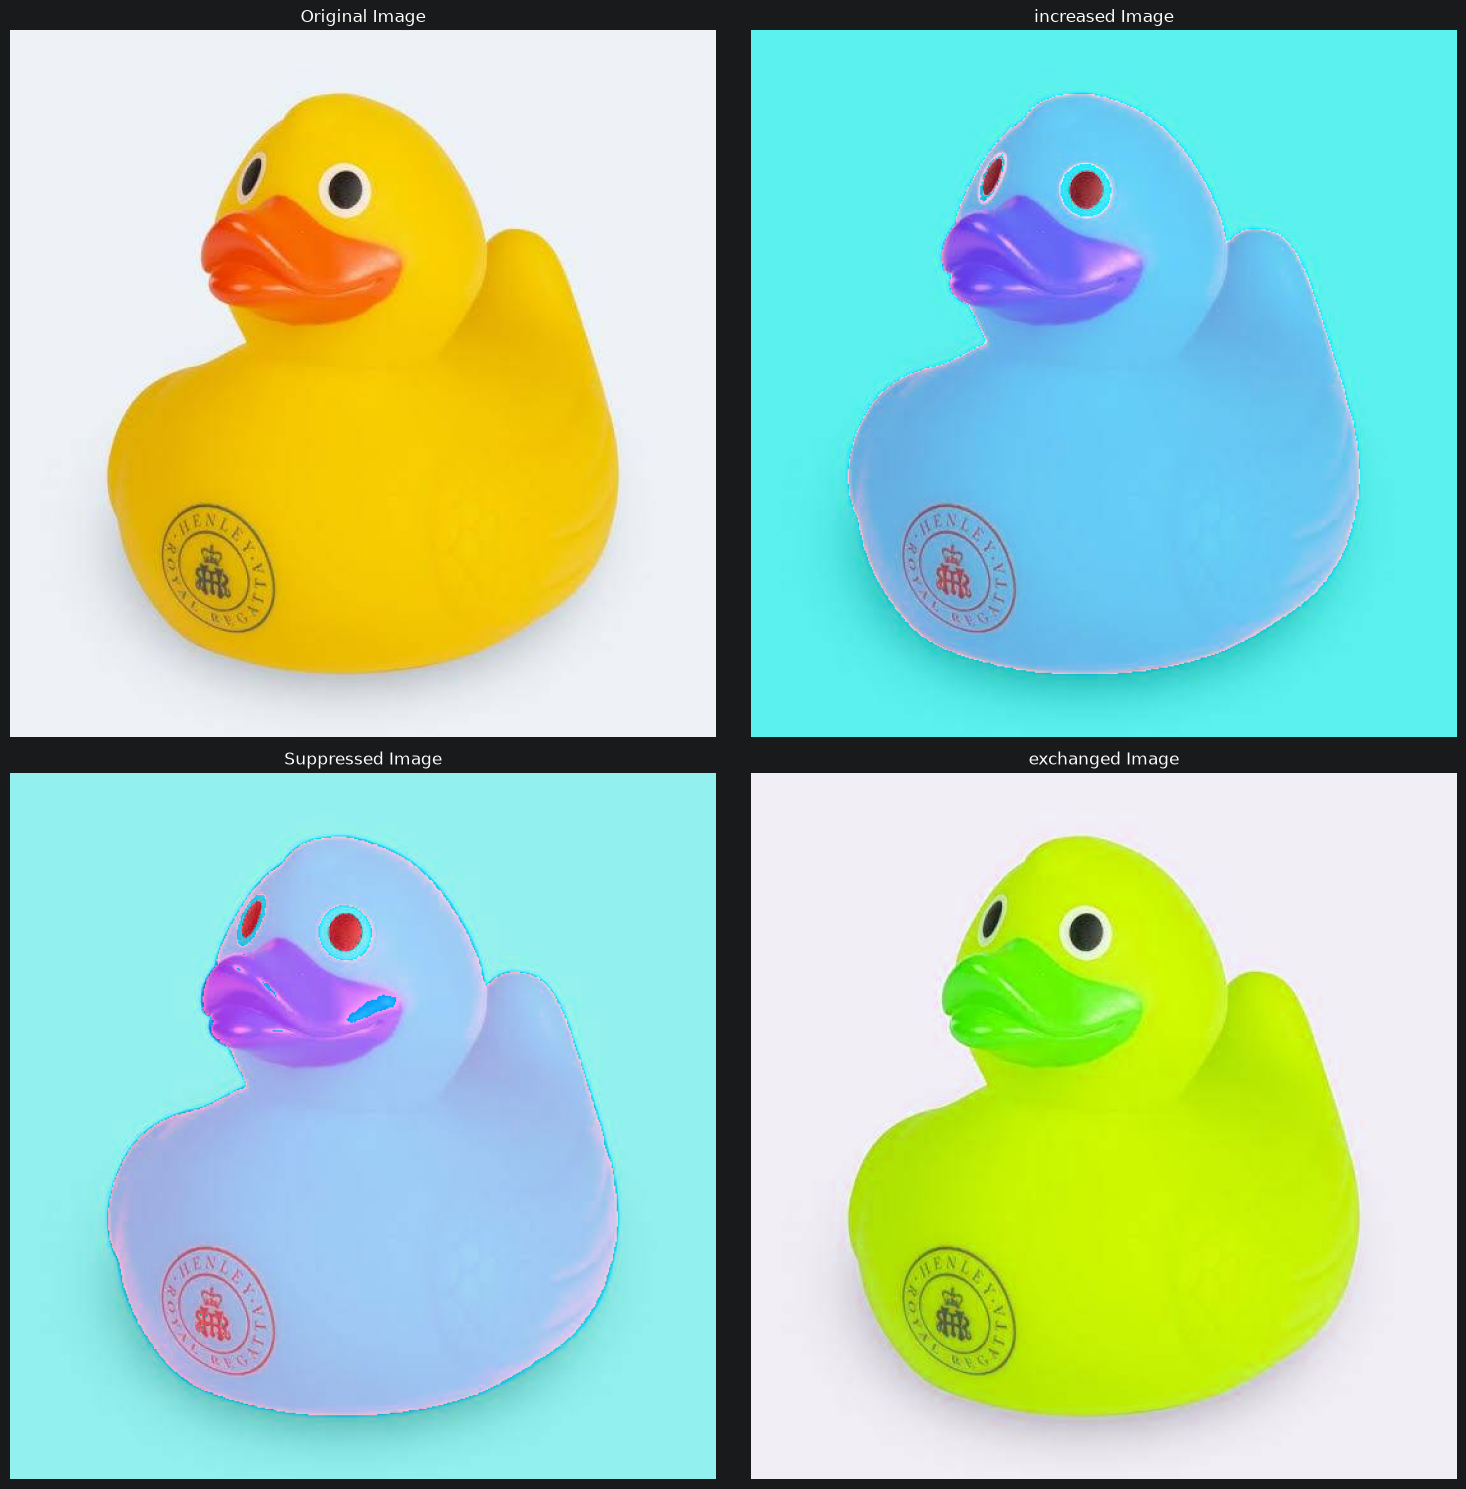

In [14]:
# TODO
B,G,R=cv2.split(duck_img)

suppress_B = np.clip( B-100, 0, 255)
increase_B = np.clip( B+100, 0, 255)

suppress_img=cv2.merge([suppress_B,G,R])
increase_img=cv2.merge([increase_B,G,R])
exchange_img=cv2.merge([G,R,B])

fig, axs = plt.subplots(2, 2, figsize=(15, 15))

axs[0,0].imshow(cv2.cvtColor(duck_img, cv2.COLOR_BGR2RGB))
axs[0,0].set_title("Original Image")
axs[1,0].imshow(suppress_img)
axs[1,0].set_title("Suppressed Image")
axs[0,1].imshow(increase_img)
axs[0,1].set_title("increased Image")
axs[1,1].imshow(exchange_img)
axs[1,1].set_title("exchanged Image")

for row in axs:
    for ax in row:
        ax.axis("off")

plt.tight_layout()
plt.show()


> **İnceleme (2026-11-04):** İki hata var.
> 1. `B` `uint8` olduğu için `B - 100` ve `B + 100` önce taşıyor, `np.clip` sonra geldiği için artık bir şey düzeltemiyor: değeri 50 olan bir piksel `B - 100` sonucunda **206** oluyor. Hesabı geniş bir tipte yap (`B.astype(np.int16)`), sonra kırp, sonra `uint8`'e dön.
> 2. `suppress_img`, `increase_img`, `exchange_img` BGR sırasında birleştirilip `plt.imshow`'a doğrudan veriliyor; renkler bu yüzden de kayıyor.
>
> Gözlemi bu iki düzeltmeden sonra yaz; yoksa iki ayrı etkiyi tek etki sanarsın. Araç 3'ün testi aynı taşma hatasını yakalayacak şekilde kuruldu.

**Gözlem 3.3 (Ex 9)** — Kanal değişikliğinin görsel etkisi ne? _(eksik)_

> ...

### Araç 3 — `excess_green`
`excess_green(bgr)`: `ExG = 2·G − R − B`. Hesabı `int16`'da yap (Ex 9 dersi), sonucu 0–255 aralığına kırp, `uint8` döndür. Yeşilin baskın olduğu yerler parlak, diğerleri koyu çıkar.

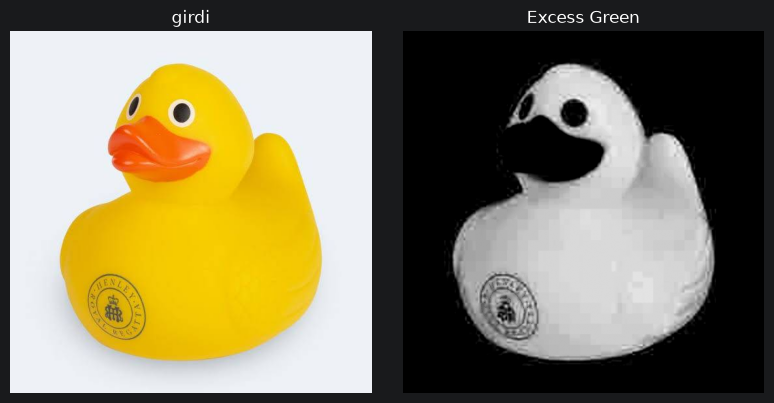

Problem 3 ✓


In [16]:
import importlib, cvtools; importlib.reload(cvtools)
from cvtools import excess_green, load_bgr, show

px = np.array([[[0, 255, 0],        # saf yeşil       -> 255 (kırpılmış)
                [128, 128, 128],    # gri             -> 0
                [0, 0, 255],        # kırmızı         -> 0 (negatif, kırpılmış)
                [0, 50, 200],       # turuncu-kırmızı -> 0 (uint8'de hesaplanırsa 156 çıkar)
                [100, 150, 100]]],  # açık yeşil      -> 100
              np.uint8)
e = excess_green(px)
assert e.shape == (1, 5) and e.dtype == np.uint8
assert e.tolist() == [[255, 0, 0, 0, 100]], f"beklenen [255, 0, 0, 0, 100], gelen {e.tolist()}"

duck = load_bgr("images/test.jpg")
show(duck, excess_green(duck), titles=["girdi", "Excess Green"])
print("Problem 3 ✓")

# Problem 4 — Bu fotoğrafın ışığı neden kötü ve ne yapmalıyım?

**Soru:** Görüntüye bakmadan, sadece sayılarına bakarak "karanlık", "aşırı parlak" ya da "normal" diyebilir miyim? Diyebiliyorsam hangi düzeltmeyi seçeceğime de karar verebilir miyim?

**Çıktı (araç):** `diagnose_exposure(gray)`

**Neden lazım:** Gerçek veri tek ışıkta gelmiyor: gölgede ve güneşte çekilmiş cepheler, farklı saatte çekilmiş hava fotoğrafları, telefonla çekilmiş eskiz kağıtları. Pipeline her görüntüye aynı düzeltmeyi körlemesine uygulamak yerine önce teşhis koymalı.

### 4.1 (Ex 10) — Gri histogram
Gri görüntünün histogramını hesapla ve çiz.

C:\Users\ekale\AppData\Local\Temp\ipykernel_23644\1601836416.py:7: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.10; the parameter will become keyword-only in 3.12.
  plt.hist(duck_gray.ravel(),239,[0,240])


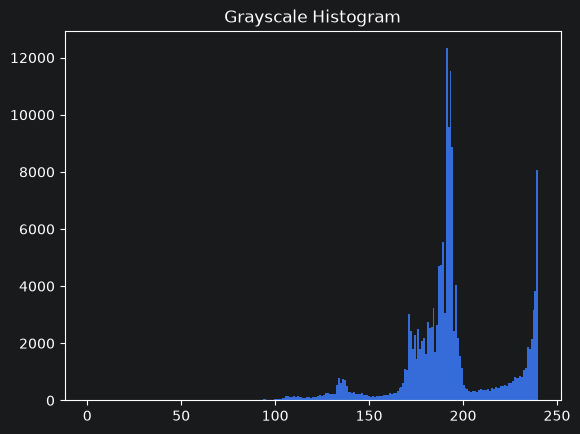

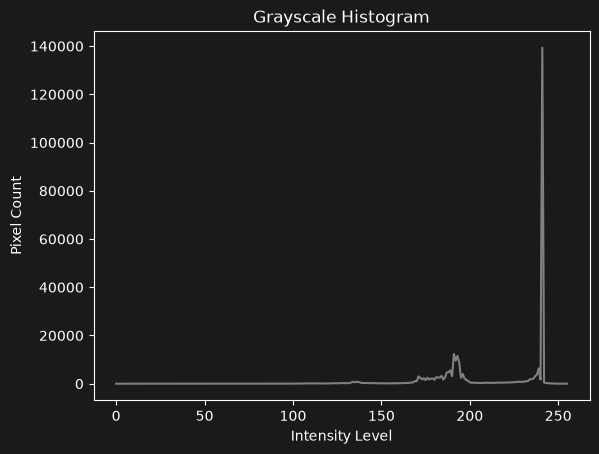

In [17]:
# TODO


duck_img=cv2.imread("images/test.jpg")
duck_gray=cv2.cvtColor(duck_img, cv2.COLOR_BGR2GRAY)

plt.hist(duck_gray.ravel(),239,[0,240])
plt.title("Grayscale Histogram")
plt.show()

# Convert the image to grayscale
gray = cv2.cvtColor(duck_img, cv2.COLOR_BGR2GRAY)

# Calculate the grayscale histogram using cv2.calcHist()
hist = cv2.calcHist([gray], [0], None, [256], [0, 256])

# Display the histogram using matplotlib
plt.plot(hist, color='gray')
plt.xlabel('Intensity Level')
plt.ylabel('Pixel Count')
plt.title('Grayscale Histogram')
plt.show()


**Gözlem 4.1 (Ex 10)** — Piksel yoğunlukları nerede toplanmış? _(eksik)_

> ...

### 4.2 (Ex 11) — Renk histogramları
Her BGR kanalı için histogram hesapla, üç dağılımı karşılaştır.

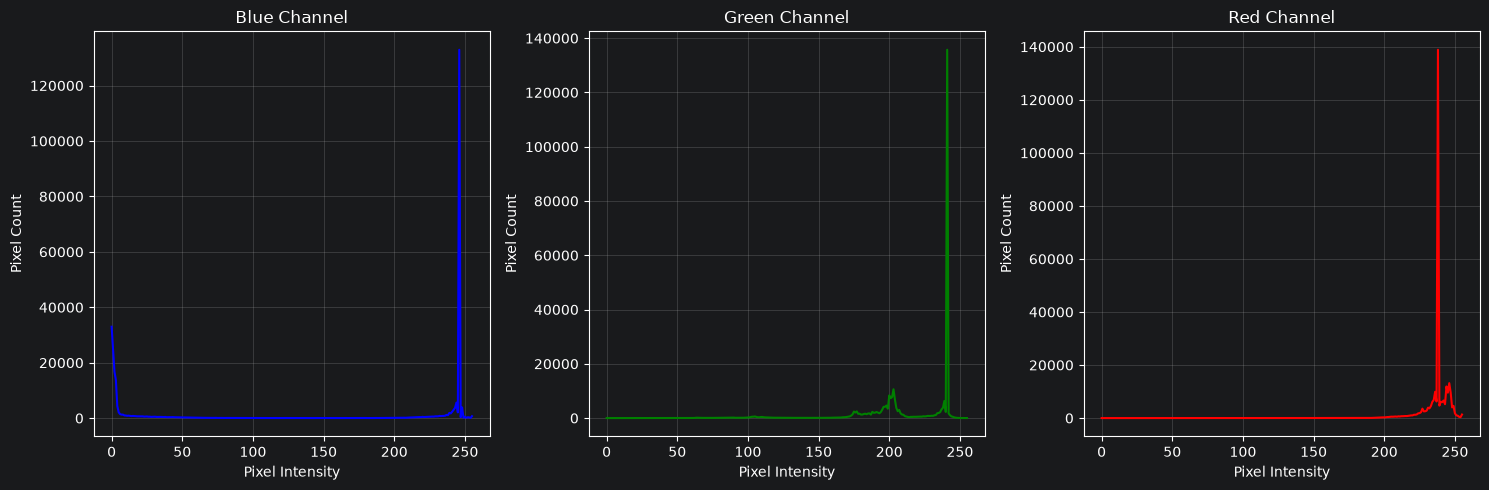

In [18]:
# TODO
duck_img=cv2.imread("images/test.jpg") #BGR

duck_b=cv2.calcHist([duck_img], [0], None, [256], [0, 256])
duck_g=cv2.calcHist([duck_img], [1], None, [256], [0, 256])
duck_r=cv2.calcHist([duck_img], [2], None, [256], [0, 256])

fig, axs = plt.subplots(1, 3, figsize=(15, 5))

axs[0].plot(duck_b, color="blue")
axs[0].set_title("Blue Channel")
axs[0].set_xlabel("Pixel Intensity")
axs[0].set_ylabel("Pixel Count")
axs[0].grid(True, alpha=0.3)

axs[1].plot(duck_g, color="green")
axs[1].set_title("Green Channel")
axs[1].set_xlabel("Pixel Intensity")
axs[1].set_ylabel("Pixel Count")
axs[1].grid(True, alpha=0.3)

axs[2].plot(duck_r, color="red")
axs[2].set_title("Red Channel")
axs[2].set_xlabel("Pixel Intensity")
axs[2].set_ylabel("Pixel Count")
axs[2].grid(True, alpha=0.3)




plt.tight_layout()
plt.show()


**Gözlem 4.2 (Ex 11)** — Baskın kanal ya da yoğunluk aralığı hakkında bir gözlem. _(eksik)_

> ...

### 4.3 (Ex 12) — Histogram bir teşhis aracı olarak
Farklı pozlamalı iki görüntünün gri histogramlarını karşılaştır. Histogram, threshold mu yoksa kontrast ayarı mı gerektiğine nasıl karar verdirir?

Bu sorunun cevabını hücrenin sonunda zaten yazmışsın; Araç 4'ün mantığı bu cevaptan çıkıyor.

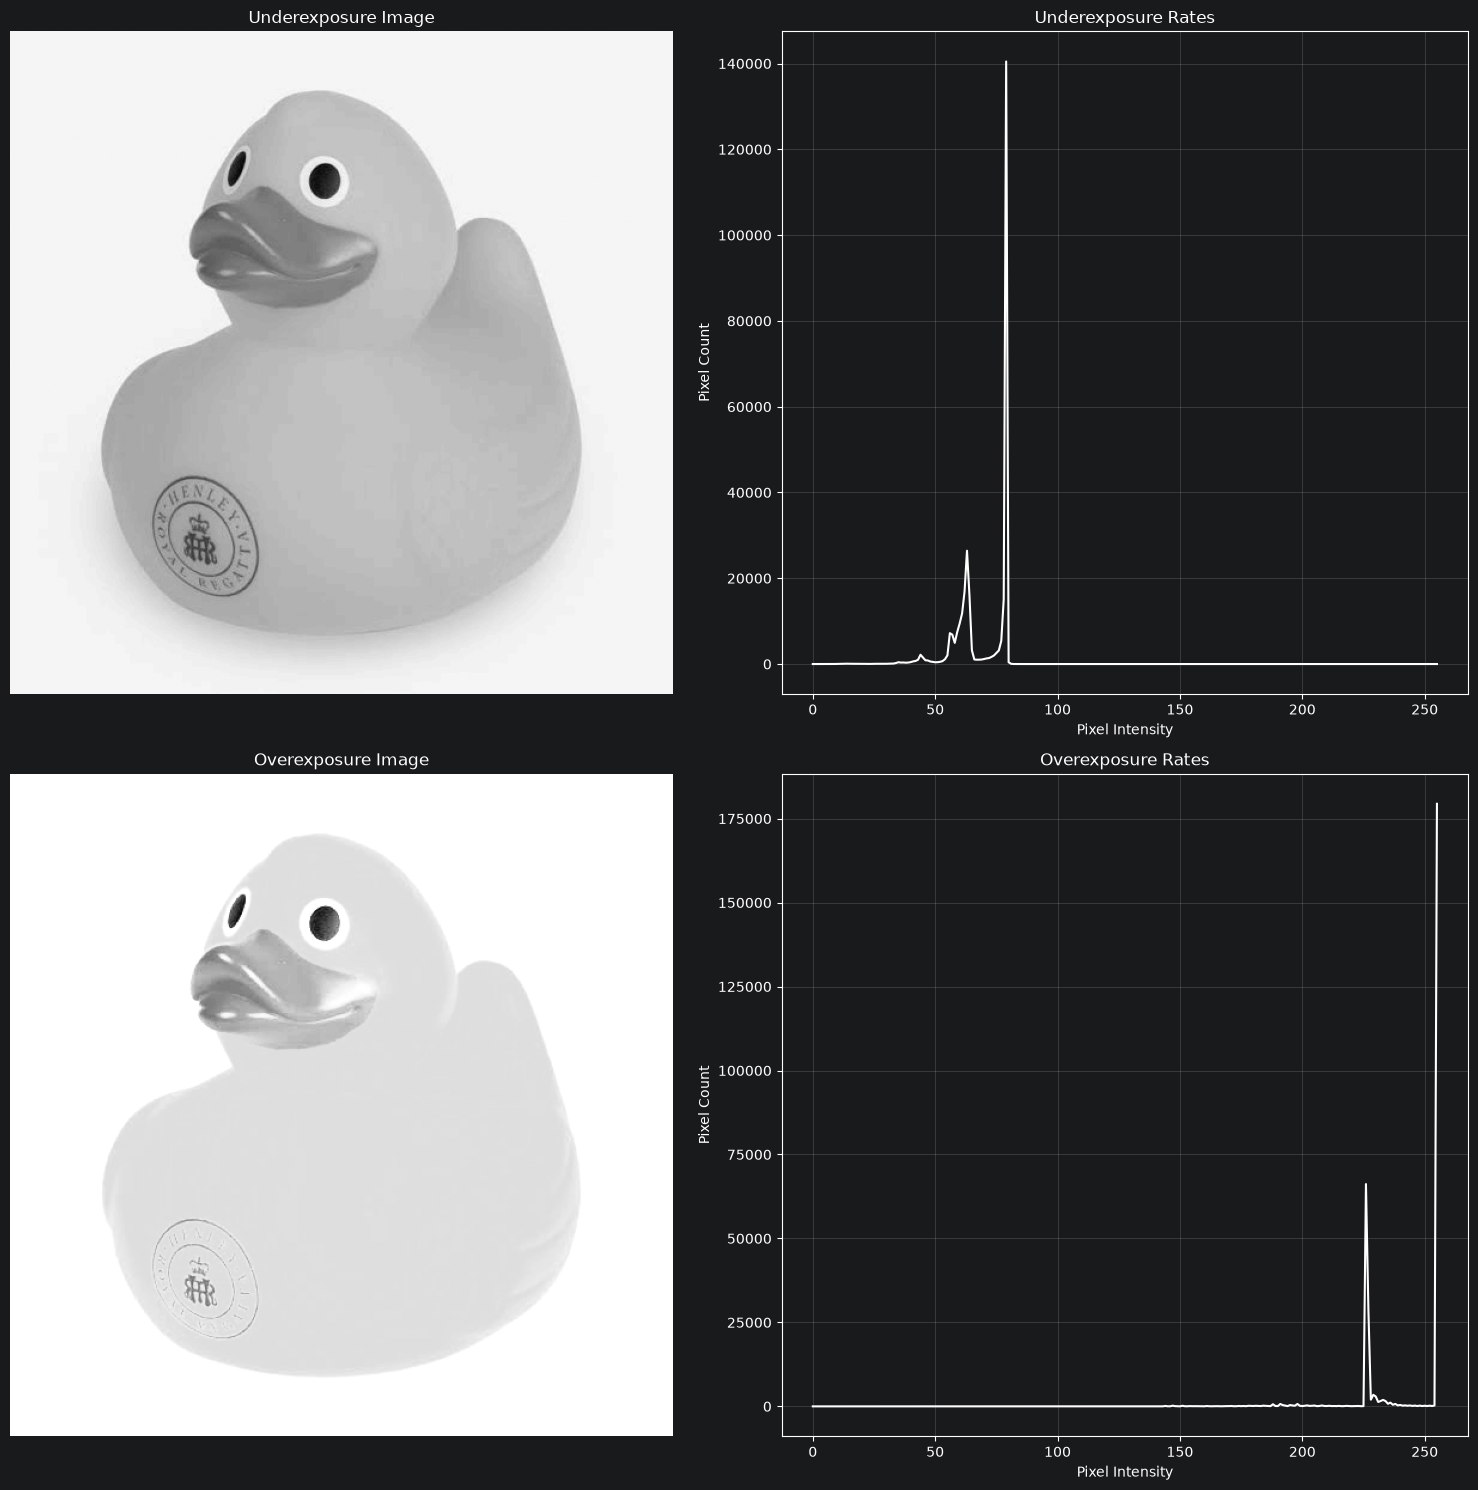

'The underexposure histogram is mostly gathered on the left side, so applying histogram equalization or increasing contrast could be beneficial. On the other hand, the overexposure histogram is mostly gathered on the right side, so decreasing contrast or brightness could be considered. Thresholding is suitable when the histogram has two distinct peaks. In this case, however, the histogram has only one peak, so contrast adjustment is more appropriate.'

In [22]:
# TODO
overexposure_img=cv2.imread("images/overexposure.png")
underexposure_img=cv2.imread("images/underexposure.png")

under_e_gray=cv2.cvtColor(underexposure_img, cv2.COLOR_BGR2GRAY)
over_e_gray=cv2.cvtColor(overexposure_img, cv2.COLOR_BGR2GRAY)

under_e_hist=cv2.calcHist([under_e_gray], [0], None, [256], [0, 256])
over_e_hist=cv2.calcHist([over_e_gray], [0], None, [256], [0, 256])

fig, axs = plt.subplots(2, 2, figsize=(15, 15))

axs[0,0].imshow(under_e_gray, cmap="gray")
axs[0,0].set_title("Underexposure Image")
axs[0,0].set_xlabel("Pixel Intensity")
axs[0,0].set_ylabel("Pixel Count")
axs[0,0].grid(True, alpha=0.3)

axs[0,1].plot(under_e_hist, color="white")
axs[0,1].set_title("Underexposure Rates")
axs[0,1].set_xlabel("Pixel Intensity")
axs[0,1].set_ylabel("Pixel Count")
axs[0,1].grid(True, alpha=0.3)

axs[1,0].imshow(over_e_gray, cmap="gray")
axs[1,0].set_title("Overexposure Image")
axs[1,0].set_xlabel("Pixel Intensity")
axs[1,0].set_ylabel("Pixel Count")
axs[1,0].grid(True, alpha=0.3)

axs[1,1].plot(over_e_hist, color="white")
axs[1,1].set_title("Overexposure Rates")
axs[1,1].set_xlabel("Pixel Intensity")
axs[1,1].set_ylabel("Pixel Count")
axs[1,1].grid(True, alpha=0.3)

#for ax in axs[:,0]:
   # ax.axis("off")

for i,row in enumerate(axs):
    row[0].axis("off")

plt.tight_layout()
plt.show()


"""The underexposure histogram is mostly gathered on the left side, so applying histogram equalization or increasing contrast could be beneficial. On the other hand, the overexposure histogram is mostly gathered on the right side, so decreasing contrast or brightness could be considered. Thresholding is suitable when the histogram has two distinct peaks. In this case, however, the histogram has only one peak, so contrast adjustment is more appropriate."""

### 4.4 (Ex 13) — Histogram eşitleme
Orijinal griyi, eşitlenmiş griyi ve iki histogramı karşılaştır.

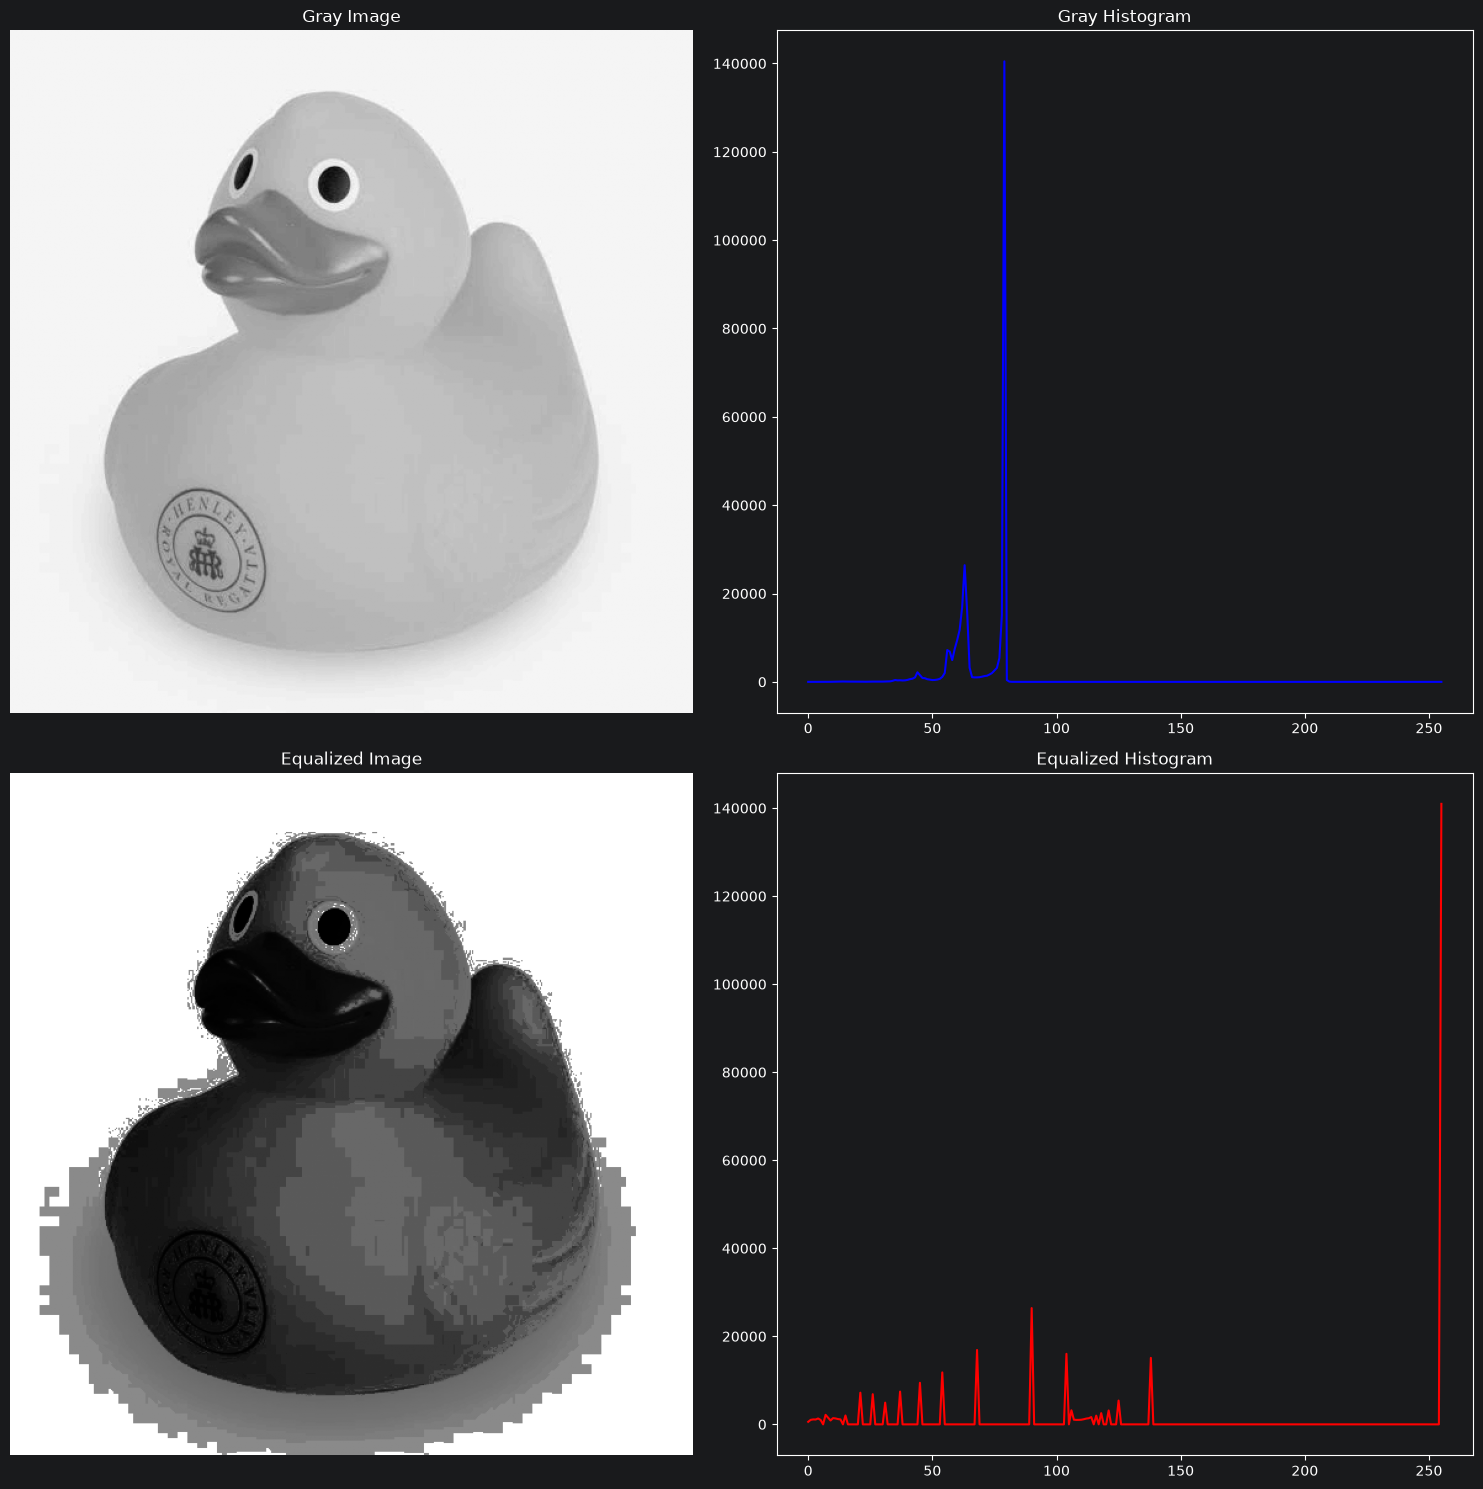

In [20]:
# TODO
duck_under_img=cv2.imread("images/underexposure.png")
duck_under_gray=cv2.cvtColor(duck_under_img, cv2.COLOR_BGR2GRAY)

hist_gray=cv2.calcHist([duck_under_gray], [0], None, [256], [0, 256])

duck_equalized=cv2.equalizeHist(duck_under_gray)
hist_equalize=cv2.calcHist([duck_equalized], [0], None, [256], [0, 256])

fig,axs=plt.subplots(2, 2, figsize=(15, 15))

axs[0,0].imshow(duck_under_gray,cmap="gray")
axs[0,0].set_title("Gray Image")

axs[0,1].plot(hist_gray, color="blue")
axs[0,1].set_title("Gray Histogram")

axs[1,0].imshow(duck_equalized,cmap="gray")
axs[1,0].set_title("Equalized Image")

axs[1,1].plot(hist_equalize, color="red")
axs[1,1].set_title("Equalized Histogram")



for i,row in enumerate(axs):
    row[0].axis("off")

plt.tight_layout()
plt.show()



**Gözlem 4.4 (Ex 13)** — Kontrast hakkında bir gözlem ve eşitleme için bir uyarı. _(eksik)_

> ...

### Araç 4 — `diagnose_exposure`
`diagnose_exposure(gray)` bir sözlük döndürür:
- `"mean"`: ortalama yoğunluk
- `"dark_ratio"`: değeri 50'nin **altında** olan piksellerin oranı (0–1)
- `"bright_ratio"`: değeri 205'in **üstünde** olan piksellerin oranı
- `"suggestion"`: `dark_ratio > 0.5` ise `"karanlık"`, `bright_ratio > 0.5` ise `"aşırı parlak"`, değilse `"normal"`

Eşikler bir başlangıç. Kendi under/overexposure görüntülerinde sonuç mantıksız çıkarsa değiştir ve nedenini not et; sentetik testler o zaman da geçmeli.

In [24]:
import importlib, cvtools; importlib.reload(cvtools)
from cvtools import diagnose_exposure, load_bgr

assert diagnose_exposure(np.full((10, 10), 20, np.uint8))["suggestion"] == "karanlık"
assert diagnose_exposure(np.full((10, 10), 240, np.uint8))["suggestion"] == "aşırı parlak"
ramp = np.tile(np.arange(256, dtype=np.uint8), (10, 1))   # 0..255 eşit dağılım
r = diagnose_exposure(ramp)
assert r["suggestion"] == "normal"
assert abs(r["dark_ratio"] - 50 / 256) < 1e-6, "dark_ratio: 50'nin altındaki piksellerin oranı"

for name in ["test.jpg", "underexposure.png", "overexposure.png"]:
    g = cv2.cvtColor(load_bgr(f"images/{name}"), cv2.COLOR_BGR2GRAY)
    print(name, diagnose_exposure(g))
print("Problem 4 ✓")

test.jpg {'mean': 214.27073857342074, 'dark_ratio': 0.001345645062492669, 'bright_ratio': 0.5772556660454327, 'suggestion': 'aşırı parlak'}
underexposure.png {'mean': 70.15462862802852, 'dark_ratio': 0.0412099727612767, 'bright_ratio': 0.0, 'suggestion': 'normal'}
overexposure.png {'mean': 241.9866347795488, 'dark_ratio': 2.9323984412673173e-05, 'bright_ratio': 0.9692130745871834, 'suggestion': 'aşırı parlak'}
Problem 4 ✓


# Problem 5 — Gürültüyü atıp kenarı nasıl korurum?

**Soru:** Bulanıklaştırmak gürültüyü siliyor ama kenarı da yumuşatıyor. Hangi yöntem, hangi gürültüde kenarı en az bozuyor?

**Çıktı (araç):** `smooth(img, method="median", k=5)`

**Neden lazım:** Threshold ve Canny gürültüye çok duyarlı (Problem 6–7). Sıva dokusu, çim dokusu, tarama gürültüsü burada bastırılmazsa sonraki her adım sahte kenar ve sahte nesne üretiyor.

### 5.1 (Ex 14) — Blur yöntemlerini karşılaştır
Average, Gaussian, median (ve senin eklediğin bilateral). Orijinalle birlikte göster.

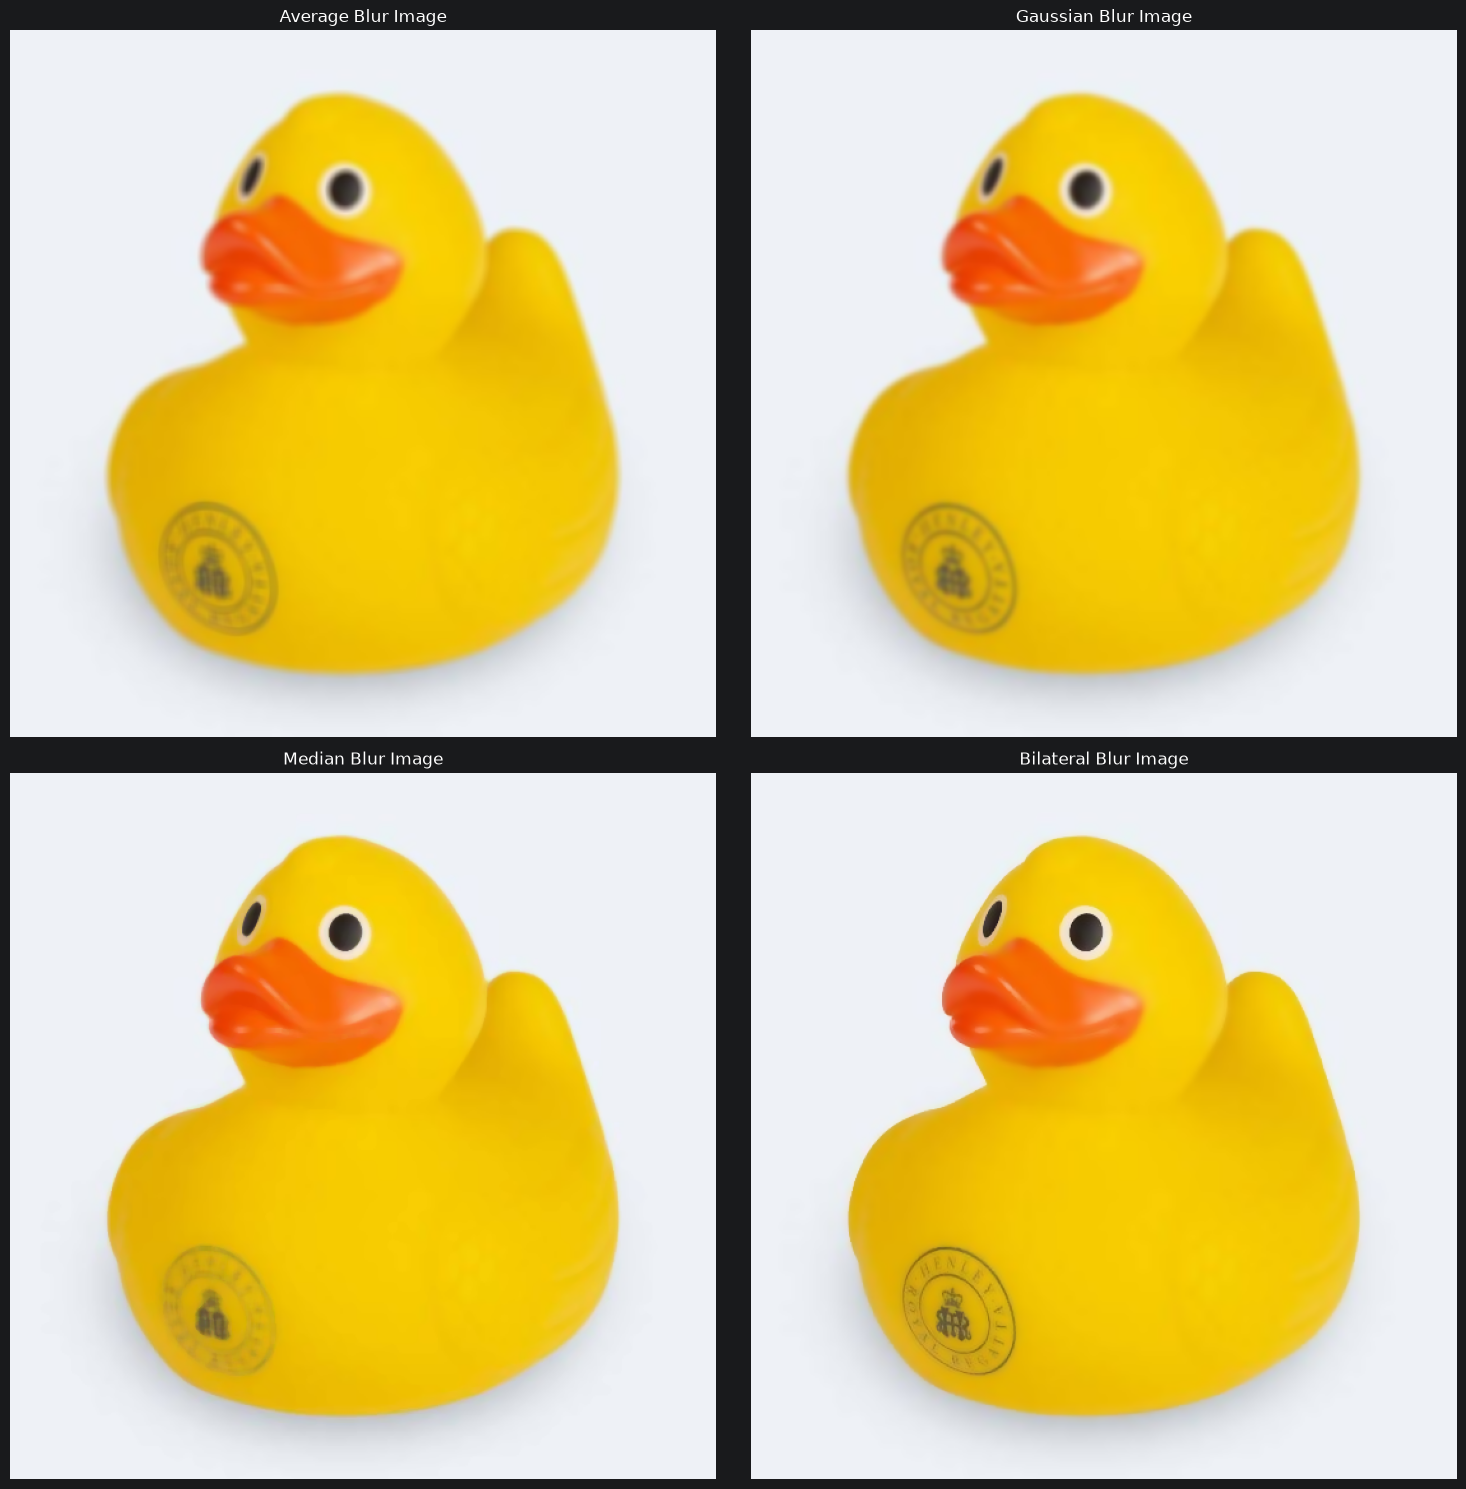

In [26]:
# TODO
duck_img=cv2.imread("images/test.jpg") #BGR

average_blur_duck=cv2.blur(duck_img,(7,7))
gaussian_blur_duck=cv2.GaussianBlur(duck_img,(11,11),0)
median_blur_duck=cv2.medianBlur(duck_img,7)
bilateral_blur_duck=cv2.bilateralFilter(duck_img,9, 75, 75)

fig,axs = plt.subplots(2, 2, figsize=(15,15))

axs[0,0].imshow(cv2.cvtColor(average_blur_duck, cv2.COLOR_BGR2RGB))
axs[0,0].set_title("Average Blur Image")

axs[0,1].imshow(cv2.cvtColor(gaussian_blur_duck, cv2.COLOR_BGR2RGB))
axs[0,1].set_title("Gaussian Blur Image")

axs[1,0].imshow(cv2.cvtColor(median_blur_duck, cv2.COLOR_BGR2RGB))
axs[1,0].set_title("Median Blur Image")

axs[1,1].imshow(cv2.cvtColor(bilateral_blur_duck, cv2.COLOR_BGR2RGB))
axs[1,1].set_title("Bilateral Blur Image")

for row in axs:
    for ax in row:
        ax.axis("off")


plt.tight_layout()
plt.show()


**Gözlem 5.1 (Ex 14)** — Bu örnekte kenarı en iyi hangisi koruyor? _(eksik)_

> ...

### 5.2 (Ex 15) — Kernel boyutu deneyi
Tek bir yöntem seç, sadece kernel boyutunu değiştir, en az üç değer dene.

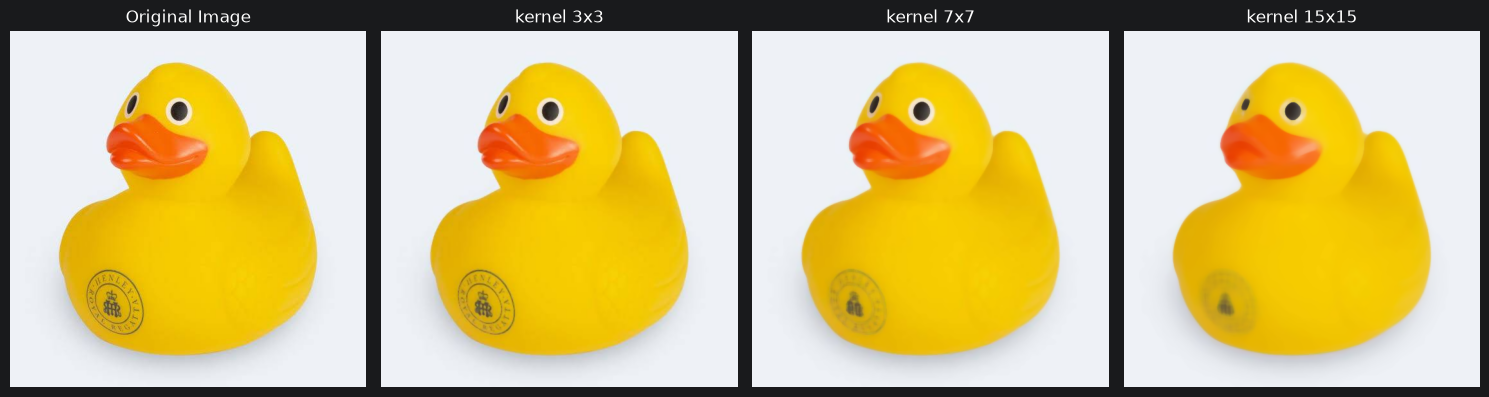

In [27]:

median_blured1=cv2.medianBlur(duck_img,3)
median_blured2=cv2.medianBlur(duck_img,7)
median_blured3=cv2.medianBlur(duck_img,15)

fig,axs= plt.subplots(1,4, figsize=(15,15))
axs[0].imshow(cv2.cvtColor(duck_img, cv2.COLOR_BGR2RGB))
axs[0].set_title("Original Image")

axs[1].imshow(cv2.cvtColor(median_blured1, cv2.COLOR_BGR2RGB))
axs[1].set_title("kernel 3x3")

axs[2].imshow(cv2.cvtColor(median_blured2, cv2.COLOR_BGR2RGB))
axs[2].set_title("kernel 7x7")

axs[3].imshow(cv2.cvtColor(median_blured3, cv2.COLOR_BGR2RGB))
axs[3].set_title("kernel 15x15")

for ax in axs:
    ax.axis("off")

plt.tight_layout()
plt.show()


**Gözlem 5.2 (Ex 15)** — Tablo: `kernel size | görsel etki | işe yarar mı` _(eksik)_

> ...

### Araç 5 — `smooth`
`smooth(img, method="median", k=5)`: `method` → `"average"`, `"gaussian"`, `"median"`, `"bilateral"`. `k` tek sayı değilse ya da `method` bilinmiyorsa `ValueError` fırlatır (OpenCV'nin kendi hatasını bekleme; kontrolü sen yap).

In [28]:
import importlib, cvtools; importlib.reload(cvtools)
from cvtools import smooth

# Tuz-biber gürültüsü: düz gri zeminde tek tek beyaz noktalar
noisy = np.full((20, 20), 128, np.uint8)
noisy[5, 5] = noisy[10, 14] = noisy[15, 3] = 255

assert (smooth(noisy, "median", 3) == 128).all(), "median 3x3 tek piksellik gürültüyü tamamen silmeli"
assert not (smooth(noisy, "average", 3) == 128).all(), "average gürültüyü siliyor mu, yayıyor mu?"

for bad in [("median", 4), ("bulanik", 3)]:
    try:
        smooth(noisy, *bad)
        raise AssertionError(f"{bad} için ValueError bekleniyordu")
    except ValueError:
        pass
print("Problem 5 ✓")

Problem 5 ✓


# Problem 6 — Bir şeyi arka plandan nasıl ayırırım?

**Soru:** Gri bir görüntüyü "nesne" ve "arka plan" diye ikiye bölmek için eşiği kim seçmeli: ben mi, histogram mı, yoksa görüntünün her bölgesi kendi eşiğini mi?

**Çıktı (araç):** `binarize(gray, method="otsu", invert=False)`

**Neden lazım:** Finalde koyu camı açık duvardan ayırmak (`invert=True`: koyu olan seçilsin), arzu yollarında açık toprağı koyu çimden ayırmak, SketchToRender'da ışığı eşit dağılmamış bir eskiz fotoğrafını temiz çizgiye çevirmek (adaptive) bu araçla yapılacak.

### 6.1 (Ex 16) — Basit eşik
En az üç eşik değeri dene, maskeleri karşılaştır.

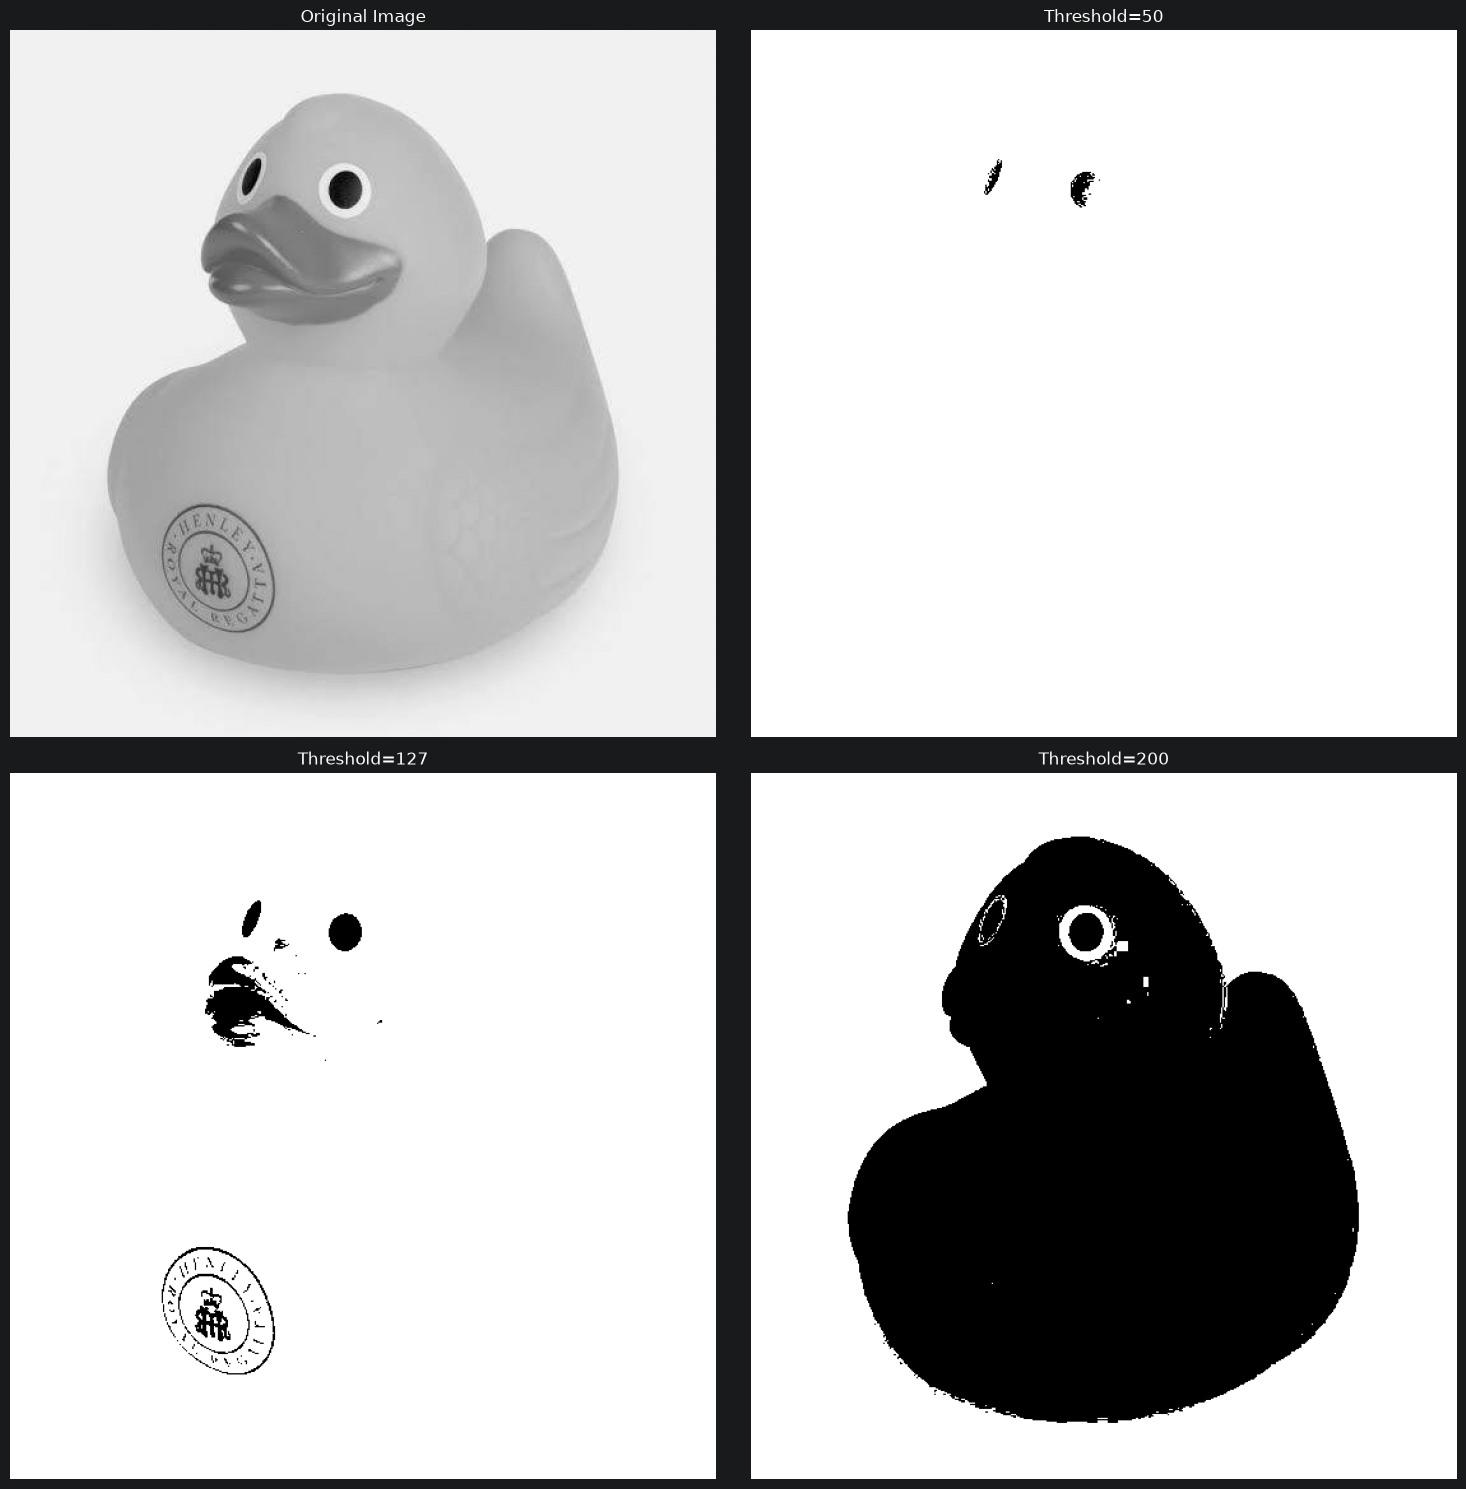

In [29]:
# TODO
duck_img=cv2.imread("images/test.jpg")

duck_gray = cv2.cvtColor(duck_img, cv2.COLOR_BGR2GRAY)

_, duck_mask_low = cv2.threshold(duck_gray,50,255,cv2.THRESH_BINARY)
_, duck_mask_mid = cv2.threshold(duck_gray,127,255,cv2.THRESH_BINARY)
_, duck_mask_high = cv2.threshold(
    duck_gray,
    200, # threshold value determines wheter the pixel is 0 or 255
    255, # max value
    cv2.THRESH_BINARY
)

fig,axs = plt.subplots(2, 2, figsize=(15,15))

axs[0,0].imshow(duck_gray, cmap="gray")
axs[0,0].set_title("Original Image")

axs[0,1].imshow(duck_mask_low, cmap="gray")
axs[0,1].set_title("Threshold=50")

axs[1,0].imshow(duck_mask_mid, cmap="gray")
axs[1,0].set_title("Threshold=127")

axs[1,1].imshow(duck_mask_high, cmap="gray")
axs[1,1].set_title("Threshold=200")

for row in axs:
    for ax in row:
        ax.axis("off")


plt.tight_layout()
plt.show()



**Gözlem 6.1 (Ex 16)** — Eşik çok düşük ya da çok yüksek olunca ne oluyor? _(eksik)_

> ...

### 6.2 (Ex 17) — Adaptive eşik
Işığı eşit dağılmamış bir görüntüde adaptive threshold uygula, global eşikle yan yana karşılaştır.

' Adaptive treshholding .....'

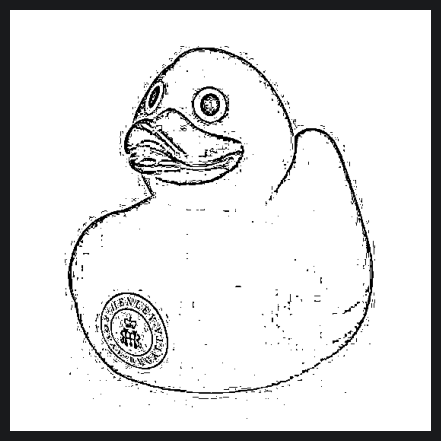

In [30]:
# TODO
adaptive_duck_mask = cv2.adaptiveThreshold(gray, 255,cv2.ADAPTIVE_THRESH_GAUSSIAN_C,cv2.THRESH_BINARY,11, 2) #c=2 or 5 or 10
plt.imshow(adaptive_duck_mask, cmap="gray")

plt.tight_layout()
plt.axis("off")
plt.show

""" Adaptive treshholding ....."""

> **İnceleme (2026-11-02):** `plt.show` parantezsiz, yani fonksiyon çağrılmıyor: `plt.show()`. Alttaki açıklama `""" Adaptive treshholding ....."""` boş kalmış. Global eşikle yan yana karşılaştır, sonra cümleyi yaz.

**Gözlem 6.2 (Ex 17)** — Adaptive eşik ne zaman daha işe yarar görünüyor? _(eksik)_

> ...

### 6.3 (Ex 18) — Otsu
Elle seçilmiş eşik ile Otsu eşiğini karşılaştır.

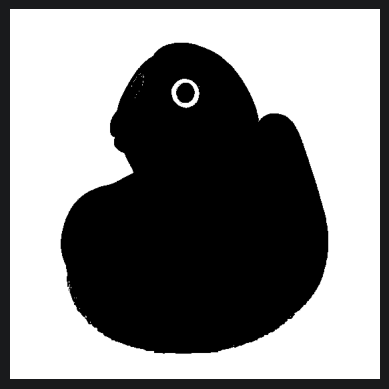

In [31]:
# TODO
ret, otsu_duck_mask = cv2.threshold(duck_gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

plt.imshow(otsu_duck_mask, cmap="gray")
plt.axis("off")
plt.show()

**Gözlem 6.3 (Ex 18)** — Elle seçilen eşik ile Otsu arasındaki fark ne? _(eksik)_

> ...

### Araç 6 — `binarize`
`binarize(gray, method="otsu", invert=False)`:
- `method`: `"otsu"`, `"adaptive"` (Gaussian, blok 11, C = 2) ya da bir tamsayı (sabit eşik)
- `invert=True` ise koyu bölgeler 255 olur
- Gri olmayan (3 kanallı) girdide `ValueError`
- Dönen: 0/255 `uint8` maske

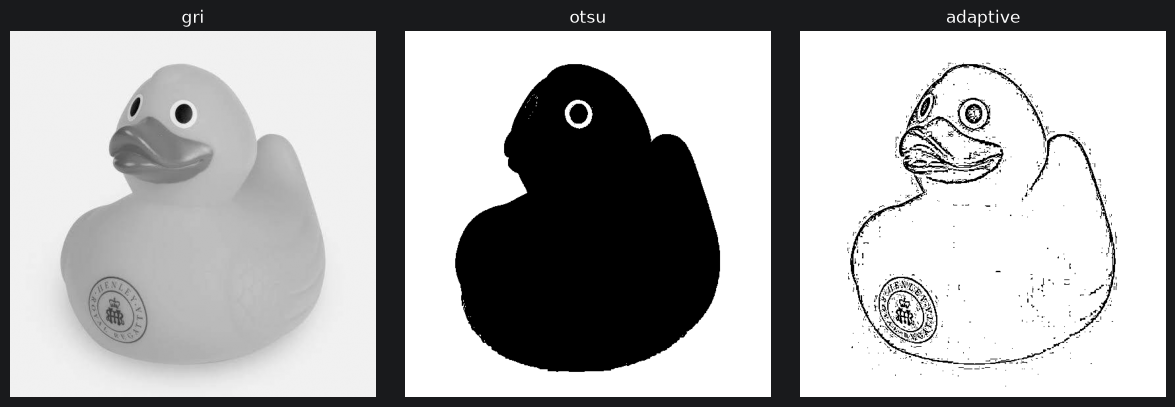

Problem 6 ✓


In [32]:
import importlib, cvtools; importlib.reload(cvtools)
from cvtools import binarize, load_bgr, show

two = np.zeros((10, 20), np.uint8)
two[:, :10] = 50
two[:, 10:] = 200
for method in ["otsu", 120]:
    m = binarize(two, method)
    assert m.dtype == np.uint8 and set(np.unique(m)) <= {0, 255}
    assert not m[:, :10].any() and m[:, 10:].all(), f"{method}: açık taraf seçilmeli"
    mi = binarize(two, method, invert=True)
    assert mi[:, :10].all() and not mi[:, 10:].any(), f"{method}: invert=True koyu tarafı seçmeli"

assert binarize(two, "adaptive").shape == two.shape
try:
    binarize(np.zeros((10, 20, 3), np.uint8))
    raise AssertionError("renkli girdide ValueError bekleniyordu")
except ValueError:
    pass

g = cv2.cvtColor(load_bgr("images/test.jpg"), cv2.COLOR_BGR2GRAY)
show(g, binarize(g, "otsu"), binarize(g, "adaptive"), titles=["gri", "otsu", "adaptive"])
print("Problem 6 ✓")

# Problem 7 — Sınır nerede?

**Soru:** Bir şeyin bittiği ve diğerinin başladığı yer, yoğunluğun hızla değiştiği yer. Bu değişimi nasıl ölçerim, hangi yönde ölçerim, ne kadarına "kenar" derim?

**Çıktı (araç):** `edge_map(gray, low, high, blur_k=0)`

**Neden lazım:** Render pipeline'larında ControlNet'in Canny koşulu tam olarak bu kenar haritasını bekliyor. Cephede Sobel X dikey çizgileri (pencere kasası, kolon), Sobel Y yatay çizgileri (döşeme, lento) öne çıkarıyor; bir pencere ikisinin birlikte kapattığı dikdörtgen.

### 7.1 (Ex 19) — Sobel X / Y
Yatay ve dikey gradyanları hesapla; gri, Sobel X, Sobel Y'yi göster. (Altındaki Scharr hücresi senin ek denemen.)

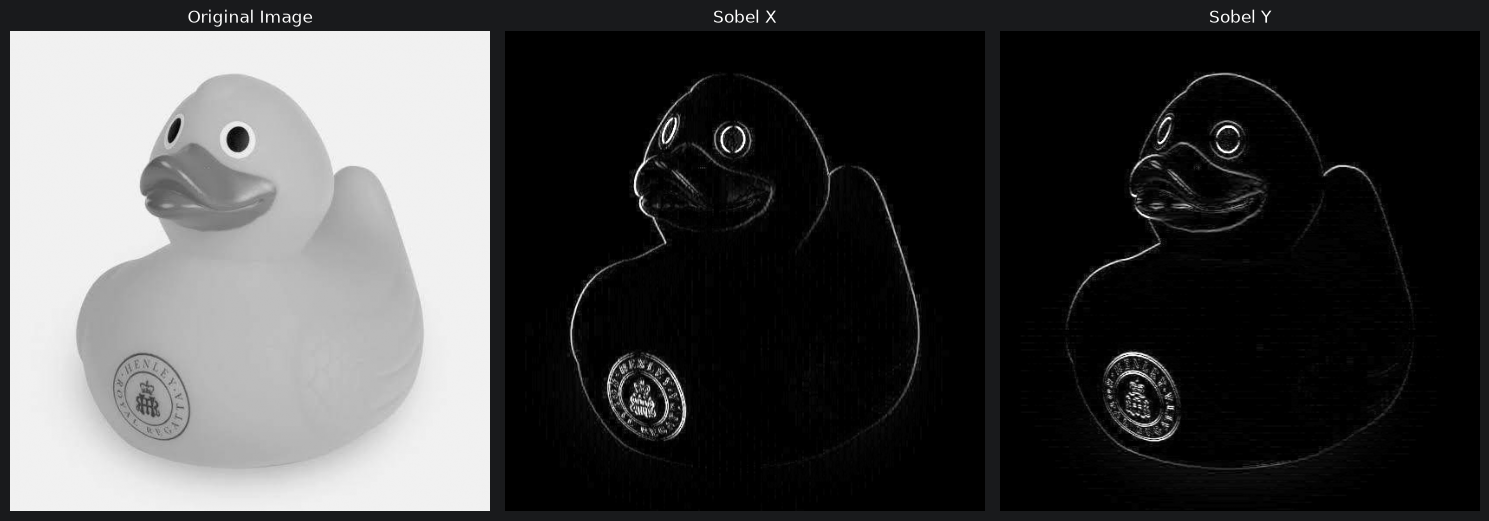

'Sobel X emphasizes vertical boundaries such as the left and right contours of the duck, while Sobel Y emphasizes horizontal boundaries such as the top of the head and the bottom edge'

In [33]:
# TODO
duck_img=cv2.imread("images/test.jpg")
duck_gray=cv2.cvtColor(duck_img,cv2.COLOR_BGR2GRAY)

sobel_x=cv2.Sobel(duck_gray,cv2.CV_64F,1,0,ksize=3)
sobel_y=cv2.Sobel(duck_gray,cv2.CV_64F,0,1,ksize=3)

sobel_x_abs=cv2.convertScaleAbs(sobel_x)
sobel_y_abs=cv2.convertScaleAbs(sobel_y)

fig,axs =plt.subplots(1,3, figsize=(15,15))

axs[0].imshow(duck_gray, cmap="gray")
axs[0].set_title("Original Image")

axs[1].imshow(sobel_x_abs, cmap="gray")
axs[1].set_title("Sobel X")

axs[2].imshow(sobel_y_abs, cmap="gray")
axs[2].set_title("Sobel Y")

for ax in axs:
    ax.axis("off")

plt.tight_layout()
plt.show()

"""Sobel X emphasizes vertical boundaries such as the left and right contours of the duck, while Sobel Y emphasizes horizontal boundaries such as the top of the head and the bottom edge"""

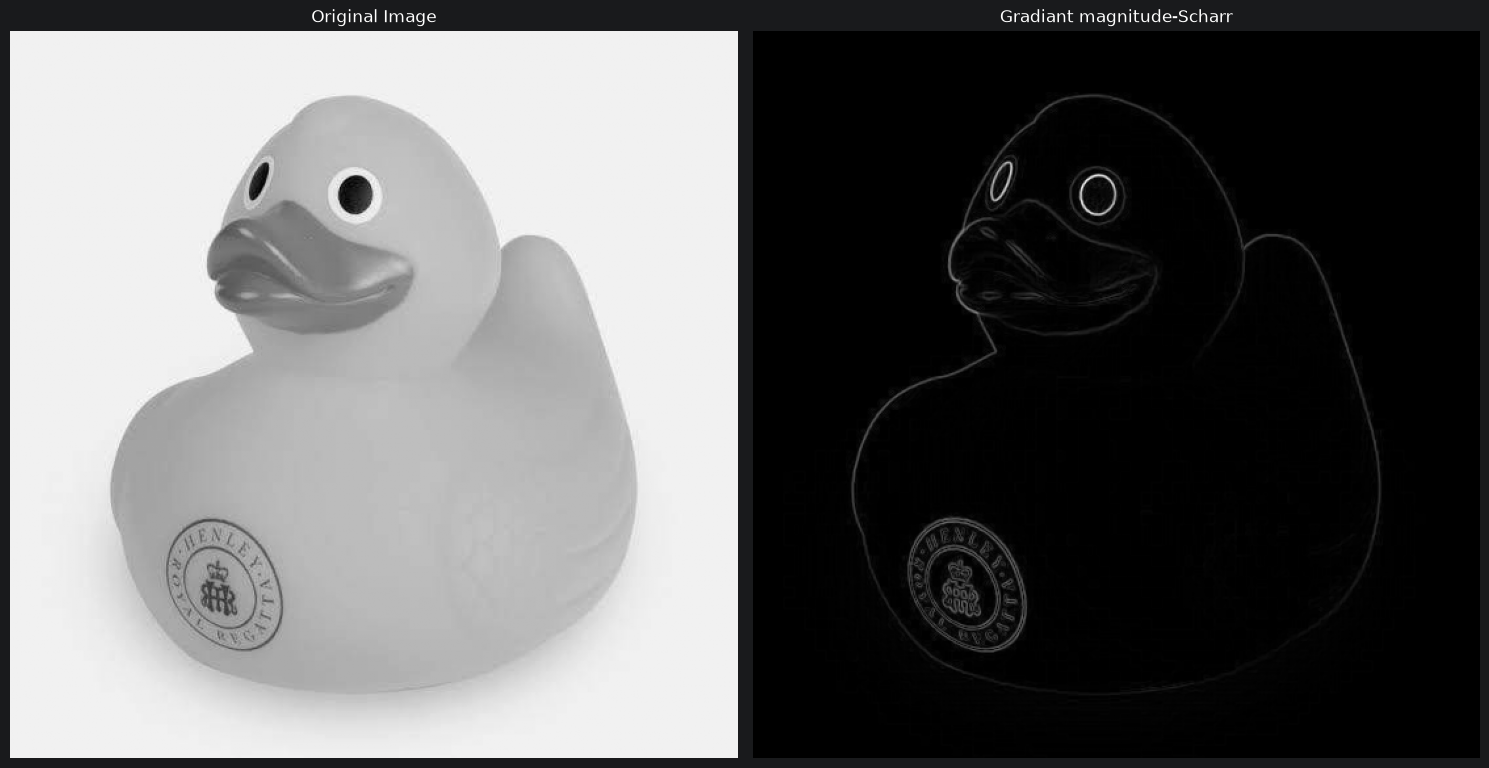

In [34]:
#Scharr>> More sensitive Sobel.

sobel_x=cv2.Scharr(duck_gray,cv2.CV_64F,1,0)
sobel_y=cv2.Scharr(duck_gray,cv2.CV_64F,0,1)

gradient_magnitude=np.sqrt(sobel_x**2+sobel_y**2)
grad_mag_normalize=cv2.normalize(gradient_magnitude,None,0,255,cv2.NORM_MINMAX,cv2.CV_8U) #it producemMore proper contrast


fig,axs =plt.subplots(1,2, figsize=(15,15))

axs[0].imshow(duck_gray, cmap="gray")
axs[0].set_title("Original Image")

axs[1].imshow(grad_mag_normalize, cmap="gray")
axs[1].set_title("Gradiant magnitude-Scharr")


for ax in axs:
    ax.axis("off")

plt.tight_layout()
plt.show()




### 7.2 (Ex 20) — Laplacian
Laplacian uygula, Sobel/Scharr ile karşılaştır, bir sınırlılığını yaz.

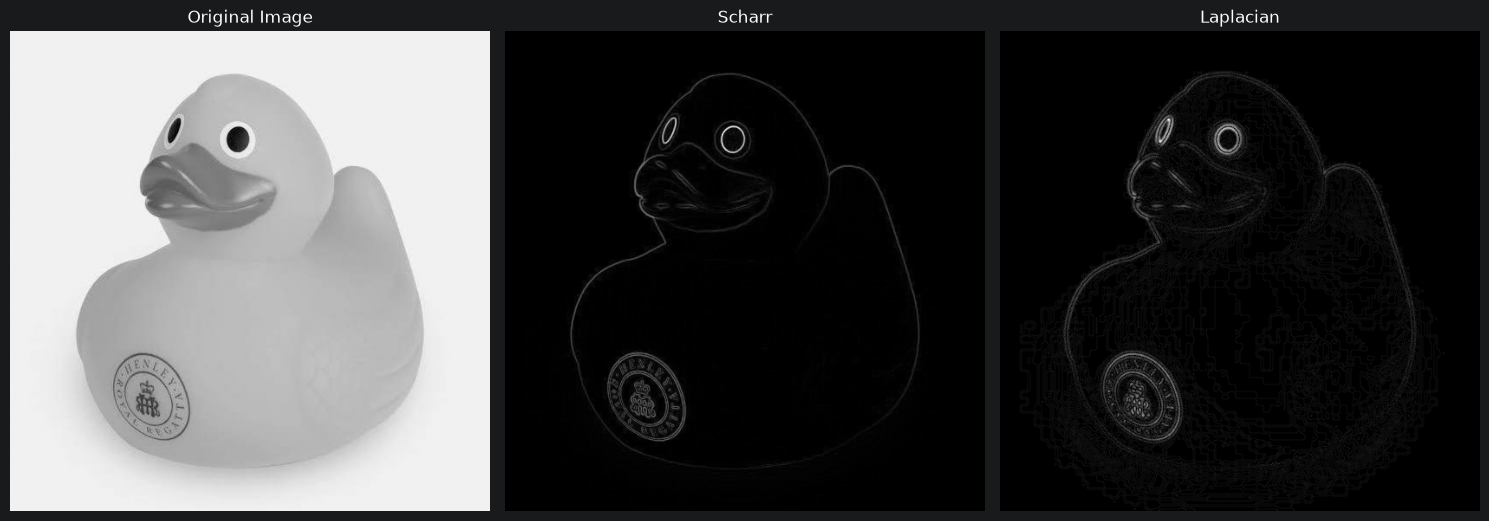

'  A key limitation of the Laplacian operator is its high sensitivity to noise. Because it uses the second derivative, it responds to any small intensity variation, so it detects not only true edges but also surface texture and noise. This makes the output much noisier and less clean compared to first-derivative operators like Sobel or Scharr.'

In [35]:
# TODO

duck_blurred = cv2.GaussianBlur(duck_gray, (7, 7), 0)

laplacian=cv2.Laplacian(duck_blurred,cv2.CV_64F)
laplacian_abs=np.absolute(laplacian)
laplacian_8u=np.uint8(laplacian_abs)



fig,axs =plt.subplots(1,3, figsize=(15,15))

axs[0].imshow(duck_gray, cmap="gray")
axs[0].set_title("Original Image")

axs[1].imshow(grad_mag_normalize, cmap="gray")
axs[1].set_title("Scharr")

axs[2].imshow(laplacian_8u, cmap="gray")
axs[2].set_title("Laplacian")

for ax in axs:
    ax.axis("off")

plt.tight_layout()
plt.show()

"""  A key limitation of the Laplacian operator is its high sensitivity to noise. Because it uses the second derivative, it responds to any small intensity variation, so it detects not only true edges but also surface texture and noise. This makes the output much noisier and less clean compared to first-derivative operators like Sobel or Scharr."""


### 7.3 (Ex 21) — Canny eşik araması
En az üç eşik çifti dene: çok fazla kenar, çok az kenar, işe yarar sonuç. En iyisini kaydet.

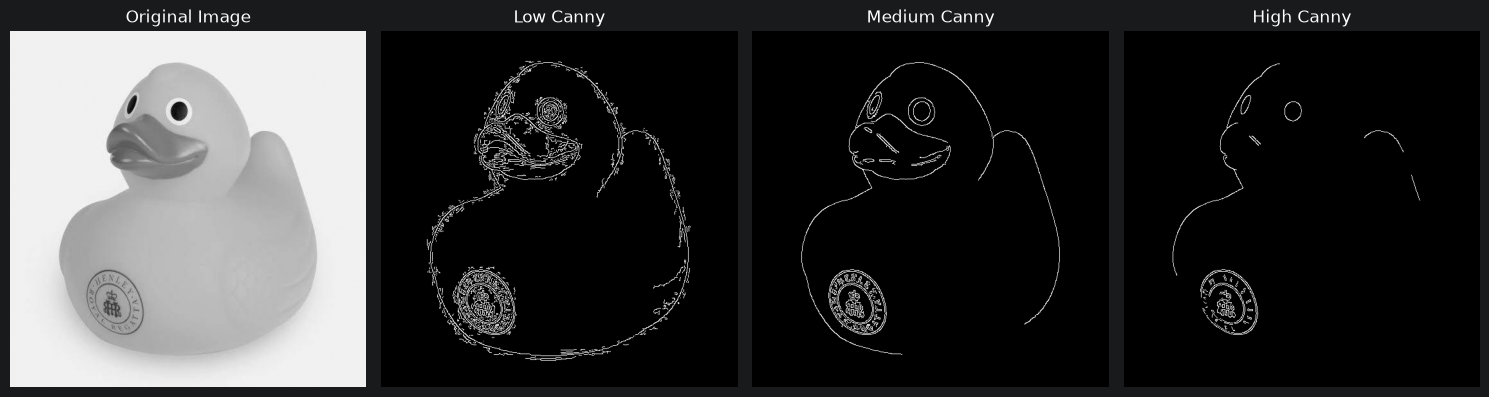

In [36]:
# TODO
duck_gray=cv2.cvtColor(duck_img,cv2.COLOR_BGR2GRAY)

#duck_blurred=cv2.GaussianBlur(duck_img,(11,11),0)

duck_edges_low=cv2.Canny(duck_gray,10,30)
duck_edges_mid=cv2.Canny(duck_gray,50,150)
duck_edges_high=cv2.Canny(duck_gray,200,300)

fig,axs =plt.subplots(1,4, figsize=(15,15))

axs[0].imshow(duck_gray, cmap="gray")
axs[0].set_title("Original Image")

axs[1].imshow(duck_edges_low, cmap="gray")
axs[1].set_title("Low Canny")

axs[2].imshow(duck_edges_mid, cmap="gray")
axs[2].set_title("Medium Canny")

axs[3].imshow(duck_edges_high, cmap="gray")
axs[3].set_title("High Canny")

for ax in axs:
    ax.axis("off")

plt.tight_layout()
plt.show()

### 7.4 (Ex 22) — Canny'den önce blur
`gri → Canny` ile `gri → Gaussian blur → Canny` karşılaştır. Blur kenar haritasını neden iyileştirebilir?

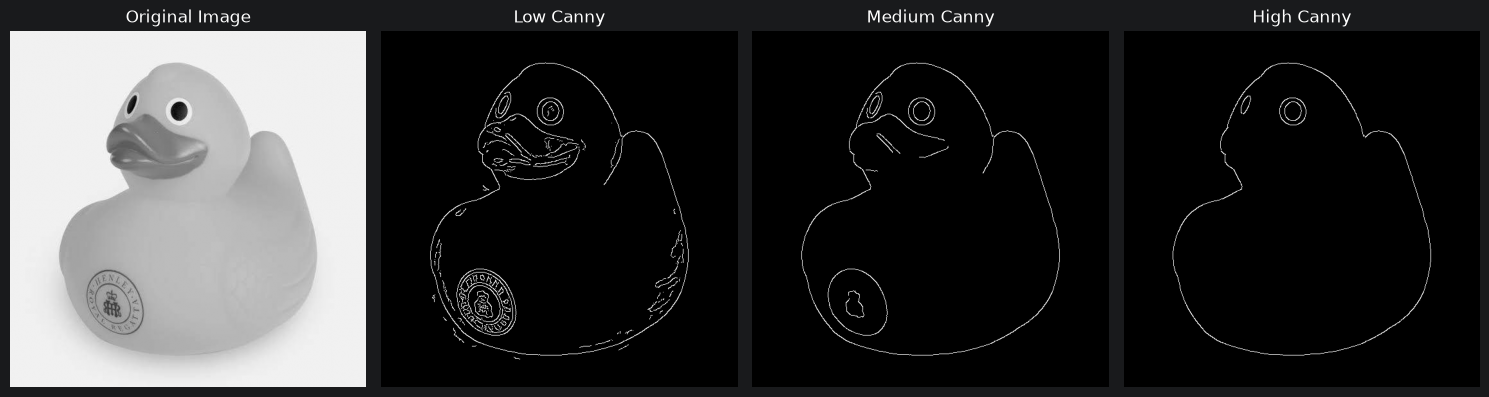

'Blur can improve the edge map because it suppresses noise before gradient computation, preventing random pixel fluctuations from being detected as false edges. However, too much blur may also remove real edges.'

In [37]:
# TODO
duck_gray=cv2.cvtColor(duck_img,cv2.COLOR_BGR2GRAY)

duck_blurred=cv2.GaussianBlur(duck_img,(11,11),0)

duck_edges_low=cv2.Canny(duck_blurred,10,30)
duck_edges_mid=cv2.Canny(duck_blurred,50,150)
duck_edges_high=cv2.Canny(duck_blurred,200,300)

fig,axs =plt.subplots(1,4, figsize=(15,15))

axs[0].imshow(duck_gray, cmap="gray")
axs[0].set_title("Original Image")

axs[1].imshow(duck_edges_low, cmap="gray")
axs[1].set_title("Low Canny")

axs[2].imshow(duck_edges_mid, cmap="gray")
axs[2].set_title("Medium Canny")

axs[3].imshow(duck_edges_high, cmap="gray")
axs[3].set_title("High Canny")

for ax in axs:
    ax.axis("off")

plt.tight_layout()
plt.show()
"""Blur can improve the edge map because it suppresses noise before gradient computation, preventing random pixel fluctuations from being detected as false edges. However, too much blur may also remove real edges."""

> **İnceleme (2026-11-02):** Ex 21'de Canny gri görüntüde, burada ise blur'lanmış **renkli** görüntüde (`GaussianBlur(duck_img)`) çalışıyor. Aynı anda iki şey değişmiş (blur + renkli/gri), üstelik kernel 11×11. Tek değişken kuralı için `duck_gray`'i blur'la, aynı üç eşik çiftini kullan, iki çıktıyı yan yana koy. Gözlem cümlen ancak o zaman bu deneye dayanır.

### Araç 7 — `edge_map`
`edge_map(gray, low, high, blur_k=0)`: `blur_k > 0` ise Canny'den önce o boyutta Gaussian blur uygular. 3 kanallı girdide `ValueError` fırlatır (`cv2.Canny` renkli görüntüyü de sessizce kabul ettiği için kontrolü sen yapmalısın). Ex 22 inceleme notundaki düzeltme bu fonksiyonun içine yerleşmiş oluyor: blur her zaman gri görüntüye uygulanır.

kenar pikseli → blur yok: 1059 | blur 5x5: 76


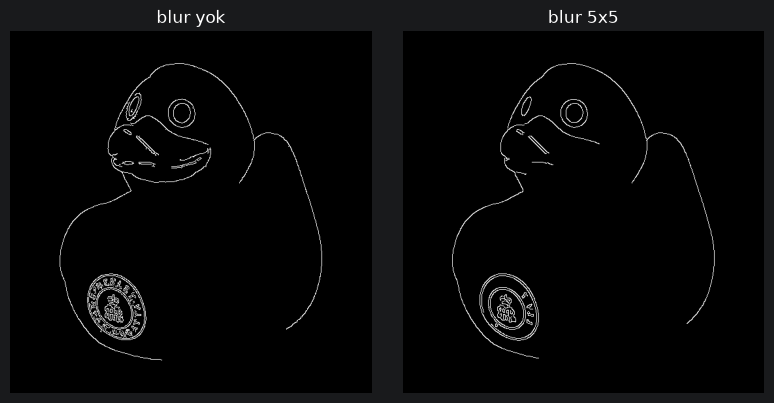

Problem 7 ✓


In [40]:
import importlib, cvtools; importlib.reload(cvtools)
from cvtools import edge_map, load_bgr, show

sq = np.zeros((60, 60), np.uint8)
sq[20:40, 20:40] = 255
e = edge_map(sq, 50, 150)
assert e.dtype == np.uint8 and set(np.unique(e)) <= {0, 255}
assert e[30, 30] == 0 and e[5, 5] == 0, "karenin içi ve dışı kenar değil"
assert e[18:42, 18:42].any(), "karenin sınırında kenar bekleniyor"

rng = np.random.default_rng(0)
noisy = np.clip(sq.astype(np.int16) + rng.normal(0, 25, sq.shape), 0, 255).astype(np.uint8)
n_raw = int((edge_map(noisy, 50, 150) > 0).sum())
n_blur = int((edge_map(noisy, 50, 150, blur_k=5) > 0).sum())
print("kenar pikseli → blur yok:", n_raw, "| blur 5x5:", n_blur)
assert n_blur < n_raw, "blur gürültüden gelen sahte kenarları azaltmalı"

try:
    edge_map(np.zeros((10, 10, 3), np.uint8), 50, 150)
    raise AssertionError("renkli girdide ValueError bekleniyordu")
except ValueError:
    pass

g = cv2.cvtColor(load_bgr("images/test.jpg"), cv2.COLOR_BGR2GRAY)
show(edge_map(g, 50, 150), edge_map(g, 50, 150, blur_k=5), titles=["blur yok", "blur 5x5"])
print("Problem 7 ✓")

# Problem 8 — Bu sınırlar kaç nesneye ait ve neredeler?

**Soru:** Elimde beyaz bölgeleri olan bir maske var. Kaç ayrı bölge var, her biri ne büyüklükte, nerede? Hangileri gürültü, hangileri nesne?

**Çıktı (araç):** `find_boxes(mask, min_area)`, `draw_boxes(bgr, boxes)`

**Neden lazım:** Sayım ve konum, final problemin cevabının kendisi: "bu cephede kaç pencere var, nerede?" ImageToRender'da eleman adaylarını ayırmak ve arzu yollarında patika parçalarını ölçmek de buradan geçiyor.

**Bu problemin ana dersi (inceleme notundan):** Kontür, Canny kenar haritasından değil, **içi dolu bir maskeden** (Problem 6'nın çıktısı) alınmalı. Kenar haritasında `contourArea` bir çizginin alanını ölçüyor; Ex 25'te 317×457'lik kutunun alanı 301 çıkması bundan.

### 8.1 (Ex 23) — Kontürleri bul
İkili bir görüntüde `cv2.findContours()`. Kontür sayısını ve her birinin alanını yazdır, kopya üzerine çiz.

In [ ]:
# 1. Görüntüyü oku ve griye çevir
duck_img = cv2.imread("images/test.jpg")
duck_gray = cv2.cvtColor(duck_img, cv2.COLOR_BGR2GRAY)

# 2. Canny ile kenarları bul (binary çıktı)
edges = cv2.Canny(duck_gray, 35, 150)

# 3. Konturları bul
contours, hierarchy = cv2.findContours(edges, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

# 4. Kontur sayısını yazdır
print(f"Number of contours: {len(contours)}")

# 5. Her konturun alanını yazdır
for i, cnt in enumerate(contours):
    area = cv2.contourArea(cnt)
    print(f"Contour {i}: Area = {area:.2f}")

# 6. Konturları orijinal görüntünün kopyası üzerine çiz
duck_copy = duck_img.copy()
cv2.drawContours(duck_copy, contours, -1, (0, 255, 0), 2)

# 7. Göster
fig, axs = plt.subplots(1, 3, figsize=(15, 5))
axs[0].imshow(cv2.cvtColor(duck_img, cv2.COLOR_BGR2RGB))
axs[0].set_title("Original")

axs[1].imshow(edges, cmap="gray")
axs[1].set_title("Canny Edges")

axs[2].imshow(cv2.cvtColor(duck_copy, cv2.COLOR_BGR2RGB))
axs[2].set_title("Contours")

for ax in axs:
    ax.axis("off")
plt.tight_layout()
plt.show()

### 8.2 (Ex 24) — Alana göre filtrele
Belirli bir alanın altındaki kontürleri at; tüm kontürleri ve filtrelenmişleri göster.

In [ ]:
# TODO
duck_gray=cv2.cvtColor(duck_img,cv2.COLOR_BGR2GRAY)

# 2. Canny ile kenarları bul (binary çıktı)
edges = cv2.Canny(duck_gray, 35, 150)

# 3. Konturları bul
contours, hierarchy = cv2.findContours(edges, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

min_area=90
#filtered_contours=[]
filtered_contours=[cnt for cnt in contours if cv2.contourArea(cnt)> min_area]
"""for cnt in contours:
    area = cv2.contourArea(cnt)
    if area > min_area:
        filtered_contours.append(cnt)"""
print(f"Number of contours: {len(contours)}")
print(f"Number of filtered_contours: {len(filtered_contours)}")
duck_copy=duck_img.copy()
duck_copy_all=duck_img.copy()
cv2.drawContours(duck_copy, filtered_contours, -1, (0, 255, 0), 2)
cv2.drawContours(duck_copy_all, contours, -1, (0, 255, 0), 2)

# 7. Göster
fig, axs = plt.subplots(1, 3, figsize=(15, 5))
axs[0].imshow(cv2.cvtColor(duck_img, cv2.COLOR_BGR2RGB))
axs[0].set_title("Original")

axs[1].imshow(cv2.cvtColor(duck_copy_all, cv2.COLOR_BGR2RGB))
axs[1].set_title("Contours")

axs[2].imshow(cv2.cvtColor(duck_copy, cv2.COLOR_BGR2RGB))
axs[2].set_title("Filtered_Contours")

for ax in axs:
    ax.axis("off")
plt.tight_layout()
plt.show()

"""Area filtering removes small noise because edge detectors like Canny often create many tiny, meaningless contours from shadows or pixel variations. By setting a minimum area threshold (e.g., min_area=90), we ignore these tiny artifacts and keep only the meaningful object boundaries (the signal)."""

> **İnceleme (2026-11-02):** Kontürler Canny **kenar** haritasından alındığı için `contourArea` kapalı bir bölgenin alanını değil, ince bir çizginin alanını ölçüyor (çoğu 0–40). Ex 25 çıktısında `w:317, h:457` boyutlu bir kutunun alanı sadece 301: bu bir çizgi, nesne değil. Nesne adayı için kontürü threshold + morfoloji maskesinden al (Ex 37, Pipeline B).

### 8.3 (Ex 25) — Sınırlayıcı kutular
Filtrelenmiş kontürler için `boundingRect` hesapla, çiz, koordinat ve alanı yazdır. Klasik CV'den nesne tespitine köprü.

In [ ]:
# TODO
# 1. Görüntüyü oku ve griye çevir
duck_img = cv2.imread("images/test.jpg")
duck_gray = cv2.cvtColor(duck_img, cv2.COLOR_BGR2GRAY)

# 2. Canny ile kenarları bul (binary çıktı)
edges = cv2.Canny(duck_gray, 35, 150)

# 3. Konturları bul
contours, hierarchy = cv2.findContours(edges, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

min_area=90
filtered_contours=[]
duck_boxes=duck_img.copy()

for cnt in contours:
    area = cv2.contourArea(cnt)
    if area > min_area:
        filtered_contours.append(cnt)
        x,y,w,h=cv2.boundingRect(cnt)
        cv2.rectangle(duck_boxes,(x,y),(x+w,y+h),(0,255,0),2)
        print(f"x:{x}, y:{y}, w:{w}, h:{h}, Area:{area}")

duck_copy=duck_img.copy()
cv2.drawContours(duck_copy, contours, -1, (0, 255, 0), 2)


# 7. Show
fig, axs = plt.subplots(1, 3, figsize=(15, 5))
axs[0].imshow(cv2.cvtColor(duck_img, cv2.COLOR_BGR2RGB))
axs[0].set_title("Original")

axs[1].imshow(cv2.cvtColor(duck_copy, cv2.COLOR_BGR2RGB))
axs[1].set_title("Contours")

axs[2].imshow(cv2.cvtColor(duck_boxes, cv2.COLOR_BGR2RGB))
axs[2].set_title("Bounding Boxes")

for ax in axs:
    ax.axis("off")
plt.tight_layout()
plt.show()



> **İnceleme (2026-11-02):** Kontürler Canny **kenar** haritasından alındığı için `contourArea` kapalı bir bölgenin alanını değil, ince bir çizginin alanını ölçüyor (çoğu 0–40). Ex 25 çıktısında `w:317, h:457` boyutlu bir kutunun alanı sadece 301: bu bir çizgi, nesne değil. Bu kutular Ex 37'de maskeyle tekrar üretilecek.

### Araç 8 — `find_boxes`, `draw_boxes`
- `find_boxes(mask, min_area)`: `RETR_EXTERNAL` ile kontürleri bulur, alanı `min_area`'dan küçük olanları atar, her biri için `(x, y, w, h, area)` döndürür; listeyi alana göre büyükten küçüğe sıralar.
- `draw_boxes(bgr, boxes)`: kutuları bir **kopya** üzerine çizer, orijinali değiştirmez.

In [ ]:
import importlib, cvtools; importlib.reload(cvtools)
from cvtools import find_boxes, draw_boxes

m = np.zeros((100, 100), np.uint8)
m[5:35, 5:25] = 255     # 20 x 30 dikdörtgen
m[50:60, 50:60] = 255   # 10 x 10 kare
m[90:92, 90:92] = 255   # 2 x 2 gürültü
boxes = find_boxes(m, min_area=50)
assert len(boxes) == 2, f"2 kutu bekleniyordu, {len(boxes)} geldi"
assert boxes[0][:4] == (5, 5, 20, 30), f"en büyük kutu ilk sırada olmalı, gelen {boxes[0][:4]}"
assert boxes[0][4] >= boxes[1][4]

canvas = np.zeros((100, 100, 3), np.uint8)
drawn = draw_boxes(canvas, boxes)
assert canvas.sum() == 0, "draw_boxes orijinali değiştirmemeli"
assert drawn.sum() > 0
print("Problem 8 ✓")

# Final Problem — Bir cephe fotoğrafında pencere adaylarını bul ve say

**Girdi:** `images/facade.jpg`. İlk deneme için önden, düz çekilmiş, pencereleri net seçilen bir cephe seç. Eğik perspektif ve ağaç gölgesi sonraki versiyonların işi.

**Çıktı:**
1. Pencere adaylarının kutulandığı görüntü → `outputs/facade_v1.png`
2. Bulunan sayı ve elle saydığın gerçek sayı
3. Kısa hata listesi: hangi pencereleri kaçırdı, neyi yanlışlıkla pencere sandı, neden

**Kural:** Bu problemde yeni görüntü işleme kodu yazmak yok; sadece `cvtools` araçlarını zincirle. Bir araç yetmezse bunu not et. Bu not Modül 1b'nin (morfoloji, Ex 31–32) giriş sorusu olacak.

**Zincir ve vereceğin kararlar:**

```text
load_bgr
diagnose_exposure          → karar: eşitleme gerekli mi?
color_mask / excess_green  → karar: gökyüzü ya da ağaç dışarıda bırakılmalı mı?
smooth                     → karar: hangi yöntem, hangi k? (sıva dokusu)
binarize                   → karar: otsu mu adaptive mi? cam koyu mu açık mı (invert)?
find_boxes                 → karar: min_area kaç?
w/h oranı filtresi         → karar: pencere oranı hangi aralıkta? (tek satırlık liste filtresi)
draw_boxes + show
```

**Beklenti:** v1 büyük ihtimalle bazı pencereleri birleştirecek ya da bölecek; camdaki yansıma, perde, doğrama ve gölge sorun çıkaracak. v1'in işi bu sorunları görünür kılmak. v2, Modül 1b'den sonra aynı fotoğrafta morfolojiyle yapılacak; v1 ve v2'yi yan yana koymak bu modülün asıl çıktısı.

In [ ]:
import importlib, cvtools; importlib.reload(cvtools)
from cvtools import *

facade = load_bgr("images/facade.jpg")

# Zinciri burada kur. Her adımdan sonra show(...) ile ara sonucu gör.

### Karar kaydı (v1)

| Adım | Seçim | Neden |
|---|---|---|
| diagnose_exposure | | |
| maske | | |
| smooth | | |
| binarize | | |
| min_area | | |
| w/h filtresi | | |

**Sonuç:** bulunan __ / gerçek __

**Hatalar ve muhtemel nedenleri:**

> ...

**Hangi araç yetmedi?** (Modül 1b'ye taşınacak soru)

> ...

## Modül 1a kapanış kontrolü

- [ ] 13 gözlem cümlesi yazıldı
- [ ] Ex 1 inceleme değerleri yazdırıldı
- [ ] Ex 6 HSV aralığı belgelendi
- [ ] Ex 9 taşma ve BGR gösterim hataları düzeltildi
- [ ] Ex 17 düzeltildi ve yorumlandı
- [ ] Ex 22 tek değişkenle yeniden yapıldı
- [ ] Problem 1–8 test hücreleri `✓`
- [ ] Final v1: `outputs/facade_v1.png` + karar kaydı
- [ ] *Restart & Run All* hatasız (Ex 6'daki fare penceresi ESC bekler)

# Ek — Serbest notlar

**Not defteri (ML taksonomisi):**

```text
1-Learning approach
    ↓
supervised / unsupervised / reinforcement

2-Model / neural network
    ↓
neural network

3-Architecture
    ↓
MLP / CNN / RNN / Transformer
    ↓
specific designs
ResNet / ViT / etc.
```